# Multilayer Perceptron Regression — Seoul Bike Sharing

ЛР2: сравнение однослойных регрессионных сетей и многослойных перцептронов для прогнозирования спроса на аренду велосипедов. В репозитории — CSV после ЛР1 и CSV после дополнительной очистки выбросов по IQR.

# Лабораторная работа #2

## Цель работы

Знакомство и работа с алгоритмом машинного обучения - нейронной сетью типа "многослойный перцептрон". Решение задачи регрессии с использованием библиотеки Tensorflow.

# Подключение библиотек

Библиотеки перечислены в `requirements.txt`. Ноутбук запускается из папки, где расположены оба CSV.

In [ ]:
import sys
print(f"Версия Python: {sys.version.split()[0]}")

In [2]:
# Python > 3.8
import pandas as pd
import numpy  as np

import sklearn
from sklearn import linear_model
from sklearn import ensemble
from sklearn import metrics
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import MinMaxScaler

%matplotlib inline
from matplotlib import pyplot as plt, cm
import seaborn as sns
import plotly.graph_objects as go
from IPython import display
import ipywidgets as widgets

import time

In [3]:
import tensorflow as tf

In [4]:
# Проверка версий библиотек
for lib in [pd, np, sklearn, tf]:
    print(f"{lib.__name__:<12} {lib.__version__}")

pandas       3.0.6
numpy        2.5.3
sklearn      1.9.1
tensorflow   2.21.0


## Объявление функций

Для повышения повторяемости кода и повышения уровня читаемости объявим несколько функций с уже знакомыми операциями

In [5]:
def PLOT34(y_test, y_pred) -> None:
    '''
    Функция построения графиков
    :param y_test: - проверочные значения целевой переменной
    :param y_pred: - вычисленные значения целевой переменной
    '''
    plt.figure(figsize=(12,6))

    # == Диаграмма рассеяния вычисленных значений ==
    # создать первое полотно 121: 1-строк, 2-столбцов, 1-индекс текущего полотна в сетке
    plt.subplot(121)
    plt.scatter(y_test, y_pred,  alpha=0.1, color = "#17becf")
    plt.axline((0, 0), slope=1, color='black', linestyle='--', linewidth=3, alpha=0.7,)
    range_test, range_pred = np.max(y_test)- np.min(y_test) , np.max(y_pred)- np.min(y_pred)
    if range_test/range_pred <4 and range_test/range_pred > 0.25:
        plt.gca().set_aspect('equal')
        axmin, axmax = np.min([y_test, y_pred]), np.max([y_test, y_pred])
        plt.xlim([axmin, axmax]); plt.ylim([axmin, axmax]);
    plt.title('Диаграмма рассеяния вычисленных значений');
    plt.xlabel('Проверочное Y');    plt.ylabel('Вычисленное Y');
    plt.grid(True,  alpha=0.5)   # Сетка

    # == Диаграмма рассеяния ошибок ==
    # создать второе полотно 121: 1-строк, 2-столбцов, 2-индекс текущего полотна в сетке
    plt.subplot(122)
    plt.scatter(y_test, (y_test - y_pred)**2,  alpha=0.1, color = "#17becf")
    plt.title('Диаграмма рассеяния квадрата абсолютной ошибки')
    plt.xlabel('Проверочное Y');    plt.ylabel('Квадрат абсолютной ошибки');
    plt.grid(True,  alpha=0.5)  # Сетка
#--------------------------------------------------------------------------

In [6]:
def GET_METRICS_SINGLE(y_test, y_pred) -> dict:
    '''
    Вычисление и вывод метрик: MAE, RMSE, R2. Используются функции из библиотеки sklearn. На основе сравнения проверочных и вычисленных значений.
    :param y_test: - проверочные значения целевой переменной
    :param y_pred: - вычисленные значения целевой переменной
    Возвращает словарь (хэш-таблицу) со значениями метрик
    '''
    mae  = metrics.mean_absolute_error        (y_test, y_pred)
    mse  = metrics.mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2   = metrics.r2_score                   (y_test, y_pred)
    print ("MAE : {:>9,.3f} (средняя абсолютная ошибка)".format              ( mae ))
    print ("MSE : {:>9,.6f} (среднеквадратичная ошибка)".format( mse ))
    print ("RMSE: {:>9,.6f} (кв. корень из среднеквадратичной ошибки)".format( rmse ))
    print ("R2  : {:>9,.3f} (коэфф. детерминации)".format                    ( r2 ))
    return {"MAE":mae, "MSE":mse, "RMSE":rmse, "R2":r2}
#--------------------------------------------------------------------------

In [7]:
def my3dplot (  x_train: pd.DataFrame, y_train: pd.DataFrame,  isDrawTrain: bool,
                x_test:  pd.DataFrame, y_test: pd.DataFrame,    isDrawTest: bool,
                y_pred:  pd.DataFrame,            isDrawPred: bool,
                x1Name: str, x2Name: str, y_targetName: str,
                pointSize = 5,     # Размер точки
                pointTransparency  = 0.25, # Прозрачность точек графика train, test
                meshTransparency   = 0.5  # Прозрачность поверхности вычисленных значений y_pred
                ) -> None:
    """
    Отображает 3D график исходных и вычисленых точек
    x_test, y_test, x_train, y_train - обучающая и проверочная части исходной таблицы  (тип DataFrame)
    y_pred, - вычисленные значения (тип DataFrame)
    x1Name, x2Name - имя столбца для x1 и x2 (тип строковый)
    y_targetName   - имя столбца целевого    (тип строковый)
    """
    # Построить поверхность, соотвествующую вычисленным значениям
    trace_ModelPredicted = go.Mesh3d(
                       x= x_test[ x1Name ].values,
                       y= x_test[ x2Name ].values,
                       z= y_pred.reshape(-1), # <-- Вычисленные
                       name="Вычисленный",
                       opacity=meshTransparency,
                       #alphahull=1,
                       color='rgb(244,100,100)',  #  rgba(100,244,100, 0.6)
                      )

    # Построить рассеяние обучающих точек
    trace_Train = go.Scatter3d (x= x_train[ x1Name ].values, # <-- Обучающие
                                y= x_train[ x2Name ].values, # <-- Обучающие
                                z= y_train[ y_targetName ].values,     # <-- Обучающие
                                name="Обучающие",
                                mode='markers',
                                marker=dict(
                                    size=pointSize,
                                    color='#1f77b4', # Цвет точек <-- Проверочные
                                    # color=y_train[ y_targetName ].values, # Источник значений цвета <-- Обучающие
                                    # colorscale='Blues',        # Название цветовой шкалы # _r
                                    opacity=pointTransparency
                                ))

    # Построить рассеяние проверочных точек
    trace_Test = go.Scatter3d ( x= x_test[ x1Name ].values,# <-- Проверочные
                                y= x_test[ x2Name ].values,# <-- Проверочные
                                z= y_test[ y_targetName ].values,    # <-- Проверочные
                                name="Проверочные",
                                mode='markers',
                                marker=dict(
                                    size=pointSize,
                                    color='#ff7f0e', # Цвет точек <-- Проверочные
                                    # color=y_test[y_targetName].values, # Источник значений цвета <-- Проверочные
                                    # colorscale='Oranges',        # Название цветовой шкалы # _r
                                    opacity=pointTransparency
                               ))

    # Составить список элементов к отрисовке на графике
    ListForDraw = []
    if isDrawTrain: ListForDraw.append(trace_Train)
    if isDrawTest:  ListForDraw.append(trace_Test)
    if isDrawPred:  ListForDraw.append(trace_ModelPredicted)

    # Отрисовать все указанные элементы
    fig = go.Figure( data=ListForDraw)

    # Добавить подписи осей
    fig.update_layout(
        width=800,
        height=600,
        title='Завиcимость {} от ({}, {})'.format(y_targetName, x1Name, x2Name),
        scene=dict(
            xaxis_title=x1Name,
            yaxis_title=x2Name,
            zaxis_title=y_targetName,
        ),
    )
    fig.show()
#--------------------------------------------------------------------------

In [8]:
def printModelWeights(model):
  # Вывод структуры и значений весовых коэфф. нейросети по слоям
  for layer in model.layers:
      print(f'{"#"*100}')
      print(f"#### Имя слоя:{layer.name};  Тип слоя: {layer.__class__} ##########", end='')
      print(f"\nВид ф-ии активации слоя: {layer.get_config()['activation']}", end='')
      print(f"\nКол-во ВХодов  слоя: {layer.input.shape[1]}", end='')
      print(f"\nКол-во ВЫХодов слоя: {layer.output.shape[1]}", end='')
      if type(layer) is tf.keras.layers.Dense:
          print(f"\nКол-во нейронов слоя:    {layer.get_config()['units']}", end='')
          print(f"\n\nВесовые коэфф. weight_i_j=\n{layer.weights[0].numpy()}")
          print(f"\nВесовые коэфф. bias_i_j=\n{layer.bias.numpy()}")
      elif type(layer) is tf.keras.layers.Activation:
          pass
      print('\n')
#-----------------------

In [9]:
def createObservationsPlot(isUseWidget = False):
  '''  Интерактивный график с двумя линиями'''
  if isUseWidget:
    # прошлый вариант c FigureWidget
    fig = go.FigureWidget(data=[
      go.Scatter(x=xNorm_train.ravel(), y=yNorm_train.ravel(), mode='lines+markers', name='Целевые',  marker=dict(color='black')),
      go.Scatter(x=xNorm_train.ravel(), y=[],  mode='lines+markers', name= f'Вычисленные нейронной сетью значения.',    marker=dict(size=5, color='tomato'))
    ])
  else:
    #  вариант  2026-10-05
    fig = go.Figure(data=[
      go.Scatter(x=xNorm_train.ravel(), y=yNorm_train.ravel(), mode='lines+markers', name='Целевые', marker=dict(color='black')),
      go.Scatter(x=xNorm_train.ravel(), y=[], mode='lines+markers', name='Вычисленные нейронной сетью значения.', marker=dict(size=5, color='tomato'))
    ])

  fig.update_xaxes(showgrid=True, gridwidth=1, gridcolor='LightGray')
  fig.update_yaxes(showgrid=True, gridwidth=1, gridcolor='LightGray')
  fig.update_layout(
      title="Соотвествие вычисл. зн. с целевыми",
      xaxis_range=[0-0.1, 1+0.1], yaxis_range=[0-0.1, 1+0.1],
      margin=dict(t=40, b=5, l=5, r=5),
      title_y=0.97,
      legend=dict(
          orientation="v",   # Set legend to horizontal
          yanchor="bottom",  xanchor="center", # Anchor the bottom of the legend
          y=-0.23,  x=0.5  ),
      width=400, height=400, )
  return fig



def initObservationsPlot(isUseWidget = False):
    ''' Подготовить и отрисовать  график '''
    fig = createObservationsPlot(isUseWidget)

    # Вар.2. Очищаем контейнер и рисуем заново внутри него
    plot_output.clear_output(wait=True)   # wait=True убирает мигание
    with plot_output:
        display.display(fig)
    # display.display(fig)

    with fig.batch_update(): # Принудительная синхронизация: пустое обновление + пауза
        yNorm_pred = model.predict(xNorm_train, verbose=0) # Вычислить ответы НС
        updateObservationsPlot(fig, 0, yNorm_pred)
    time.sleep(2)  # Дать браузеру время отрисовать виджет
    return fig

def updateObservationsPlot(fig, currEpochNum, yNorm_pred, history=None): #, , epochForTrainInRound
    ''' Обновить значения графика (использует глобалные переменные) '''
    with fig.batch_update(): # Plotly. Обновляем данные внутри виджета напрямую
        fig.update_layout(title_text=f"Соотвествие вычисл. зн. с целевыми.<br>Эпоха: {globalEpochCounter} (текущая {currEpochNum} из {epochForTrainInRound})")
        fig.data[1].y =  yNorm_pred.ravel()
        if history:
            fig.data[1].name = f'Вычисленные нейронной сетью. MSE {history.history["loss"][-1]:>9.6f}'
        else:
            fig.data[1].name = f'Вычисленные нейронной сетью.'


In [10]:
# ── Живой график обучения (без ipywidgets) и итоговая анимация ─────────────────
import io

def figToImage(fig):
    ''' Отрисовать matplotlib-рисунок в PNG фиксированного размера '''
    buf = io.BytesIO()
    fig.savefig(buf, format='png')  # без bbox_inches='tight' -> размер картинки не меняется, график не "прыгает"
    return display.Image(data=buf.getvalue())

def createLivePlot(x, y_true):
    ''' Создать график и вывести его с display_id, чтобы потом обновлять "на месте" (без clear_output) '''
    fig, ax = plt.subplots(figsize=(7, 4.5), dpi=90)
    ax.scatter(x, y_true, s=markerSize, color="black", alpha=transparencyVal, label="Исходные данные")
    predLine, = ax.plot(np.ravel(x), np.full(len(x), np.nan), '.', color="red", markersize=3, label="Вычисленные НС")
    ax.set_xlim(-0.1, 1.1);  ax.set_ylim(-0.1, 1.1)
    ax.set_xlabel("Объясняющий X");  ax.set_ylabel("Целевой Y")
    ax.grid(True, alpha=0.5)
    plt.close(fig)  # чтобы inline-бэкенд не вывел этот рисунок ещё раз в конце ячейки
    handle = display.display(figToImage(fig), display_id=True)
    return fig, predLine, handle

def updateLivePlot(fig, predLine, handle, yNorm_pred, title, loss=np.nan):
    ''' Обновить линию ответов НС и заменить картинку в том же месте вывода '''
    predLine.set_ydata(np.ravel(yNorm_pred))
    predLine.set_label(f"Вычисленные НС. loss {loss:.6f}")
    fig.axes[0].legend(loc='lower right')
    fig.axes[0].set_title(title)
    handle.update(figToImage(fig))

def showTrainingAnimation(x, y_true, snapshots, maxFrames=80, frameDuration=150):
    ''' Plotly-анимация по накопленным снимкам ответов НС (кнопки Play/Pause и ползунок по эпохам) '''
    if not snapshots:
        print("Нет сохранённых снимков - сначала выполните обучение"); return
    step  = int(np.ceil(len(snapshots) / maxFrames))  # прореживание, чтобы анимация не была слишком тяжёлой
    shots = snapshots[::step]
    if shots[-1] is not snapshots[-1]: shots.append(snapshots[-1])  # последний снимок показываем всегда

    x = np.ravel(x)
    def predTrace(s):
        return go.Scatter(x=x, y=s['y'], mode='markers', marker=dict(size=4, color='tomato'), name="Вычисленные НС")
    def frameTitle(s):
        return f"Эпоха {s['epoch']}  |  loss {s['loss']:.6f}"

    frames = [go.Frame(name=str(s['epoch']), data=[predTrace(s)], traces=[1],
                       layout=go.Layout(title_text=frameTitle(s))) for s in shots]
    fig = go.Figure(
        data=[go.Scatter(x=x, y=np.ravel(y_true), mode='markers', marker=dict(size=4, color='black'), opacity=0.3, name='Целевые'),
              predTrace(shots[0])],
        frames=frames)

    animArgs = lambda duration: dict(frame=dict(duration=duration, redraw=True), transition=dict(duration=0), mode='immediate')
    fig.update_layout(
        title_text=frameTitle(shots[0]), width=650, height=520,
        xaxis=dict(range=[-0.1, 1.1], title="Объясняющий X"), yaxis=dict(range=[-0.1, 1.1], title="Целевой Y"),
        margin=dict(t=70, b=110),
        legend=dict(orientation='h', x=1, y=1.02, xanchor='right', yanchor='bottom'),
        updatemenus=[dict(type='buttons', direction='left', showactive=False, x=0, y=-0.13, xanchor='left', yanchor='top',
                          buttons=[dict(label='▶ Play',  method='animate', args=[None, {**animArgs(frameDuration), 'fromcurrent': True}]),
                                   dict(label='❚❚ Pause', method='animate', args=[[None], animArgs(0)])])],
        sliders=[dict(active=0, x=0.22, len=0.78, y=-0.08, currentvalue=dict(visible=False),  # номер эпохи уже есть в заголовке
                      steps=[dict(method='animate', label=f.name, args=[[f.name], animArgs(0)]) for f in frames])],
    )
    fig.show()
#----------------------------------------------------------------------

In [11]:
class GlobalEpochLogger(tf.keras.callbacks.Callback):
    '''  Модифицированный Callback - перехватывает события обучения и выводит нужное сообщение. '''
    def __init__(self):
        super().__init__()
    def on_epoch_end(self, local_epoch, logs=None):
        logs = logs or {}
        loss = logs.get("loss", float("nan"))
        val  = logs.get("val_loss", None)
        val_str = f"  val_loss: {val:.6f}" if val is not None else ""
        print(f"\rЭпоха {globalEpochCounter:>5} (текущая {currEpochNum} из {epochForTrainInRound}) | loss: {loss:.6f}{val_str}", end="", ) #flush=True
#----------------------------------------------------------------------
logShortener = GlobalEpochLogger()

# Tensorflow. Проверка работы нейросети на искусственных данных

Получим модель НС, обученную на  почти "идеальных" входных данных, т.е. с четко прослеживаемой зависимостью переменных и контролируемым уровнем шумов.

Цель данного шага - продемонстрировать работоспособность применения НС для решения задачи регрессии.

## Набор данных для демонстрации

Создадим несколько искусственных наборов данных с явной зависимостью ЕДИНСТВЕННОГО `y` от ЕДИНСТВЕННОГО `x`.

После создания преобразуем данные к типу **pandas.DataFrame**, т.к. загруженные данные по варианту будут иметь указанный тип.

Создадим переменную `X` как набор значений области определения функции в диапазоне  [-1.0, 1.0].

In [12]:
N = 1000 # кол-во точек X
X = np.linspace(-1., 1., N).reshape(-1, 1) # привести массив к столбчатой структуре

Получим набор значения для имитации случайных отклонений для зависимой величины `y`.

In [13]:
noiseLevel= 0.05 # степень зашумленности
Y_noise = np.random.normal(-noiseLevel,noiseLevel,N).reshape(-1, 1)

Объявим вспомогательные переменные для отображения дальнейших графиков.

In [14]:
transparencyVal = 0.3  # Прозрачность точек графика
markerSize = 10        # Размер точки графика



Используя функции различного вида, получим значения `y` для каждого `x`.

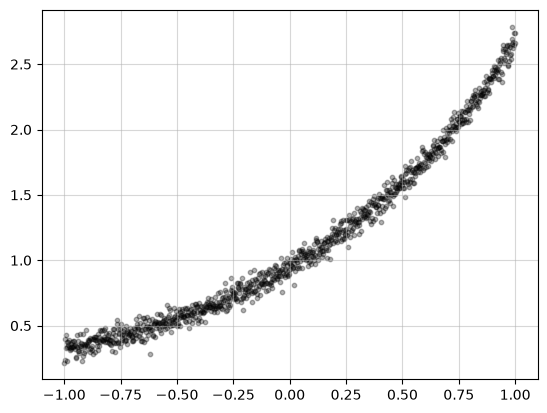

In [15]:
# Экспонента
Y_exp = np.exp(X).reshape(-1, 1) # привести массив к столбчатой структуре
Y_exp= Y_exp+Y_noise
plt.scatter(X, Y_exp, s=markerSize, color="black", alpha=transparencyVal) # Точечная диаграмма
plt.grid(True, alpha=0.5)  # Сетка

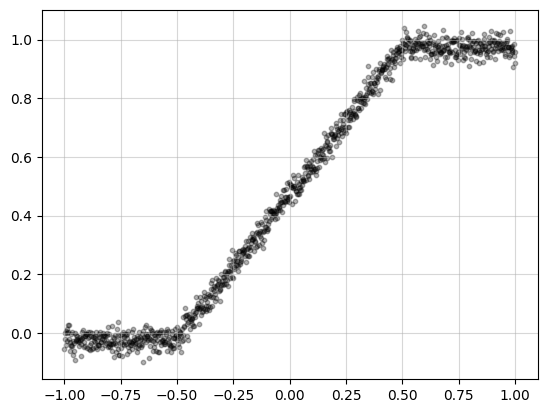

In [ ]:
# Линейный с граничными значениями
c1 = int(X.size * 0.25)
c2 = int(X.size * 0.50)
c3 = X.size - c1 - c2

Y_linstep = np.concatenate([
        np.zeros( c1 ),
        np.linspace(start=0., stop=1., num=c2),
        1.0 + np.zeros(c3 )
        ],
    ).reshape(-1, 1)# привести массив к столбчатой структуре

Y_linstep= Y_linstep+Y_noise/2
plt.scatter(X, Y_linstep, s=markerSize, color="black", alpha=transparencyVal) # Точечная диаграмма
plt.grid(True, alpha=0.5)  # Сетка

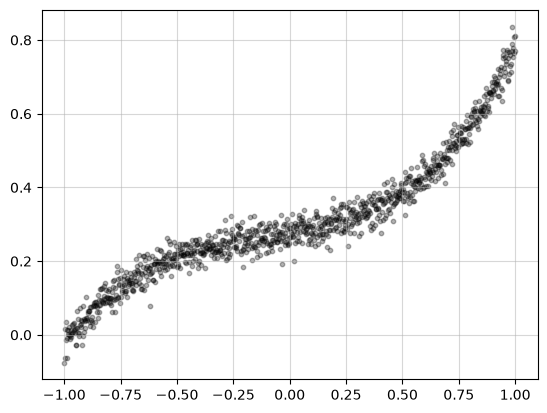

In [16]:
# Полином
Y_polyn = (0.3*(X**3) + 0.1*(X**2) + 0.1 * X + 0.3).reshape(-1, 1) # привести массив к столбчатой структуре
Y_polyn = Y_polyn + Y_noise/2
plt.scatter(X, Y_polyn, s=markerSize, color="black", alpha=transparencyVal) # Точечная диаграмма
plt.grid(True, alpha=0.5)  # Сетка

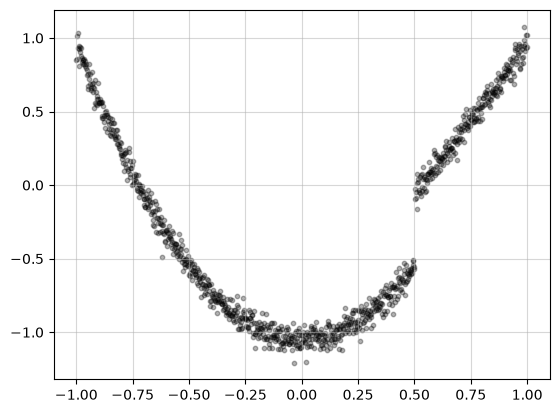

In [17]:
# Парабола
f1 = lambda x: ((x < .5) * np.power(x, 2) + (x > .5) * x) * 2 -1
Y_parabola = f1(X).reshape(-1, 1) # привести массив к столбчатой структуре
Y_parabola = Y_parabola + Y_noise
plt.scatter(X, Y_parabola, s=markerSize, color="black", alpha=transparencyVal) # Точечная диаграмма
plt.grid(True, alpha=0.5)  # Сетка

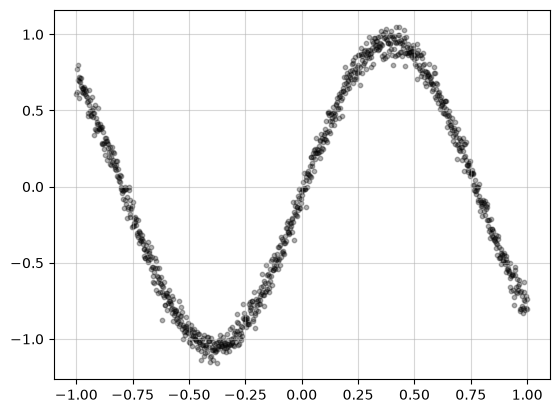

In [18]:
# Синусоида
Y_sin = np.sin(4 * X).reshape(-1, 1) # привести массив к столбчатой структуре
Y_sin = Y_sin + Y_noise
plt.scatter(X, Y_sin, s=markerSize, color="black", alpha=transparencyVal) # Точечная диаграмма
plt.grid(True, alpha=0.5)  # Сетка

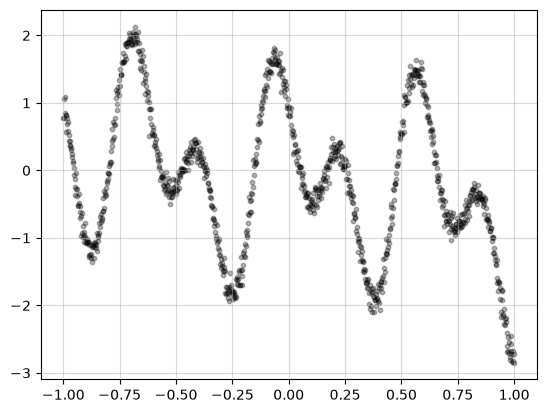

In [19]:
# Наложение циклических функций
Y_hard = np.cos(X*10)  - 1*np.sin(20*X) - 1*X**3
Y_hard = Y_hard+Y_noise*2
plt.scatter(X, Y_hard, s=markerSize, color="black", alpha=transparencyVal) # Точечная диаграмма
plt.grid(True, alpha=0.5)  # Сетка

В итоге мы получим несколько наборов данных, доступных для выбора в качестве обучающих данных для НС.
- Y_exp - Экспонента
- Y_linstep - Линейная с граничными значениями
- Y_polyn - Полином
- Y_parabola - Парабола
- Y_sin - Синусоида
- Y_hard - Наложение циклических функций

Выберите один из наборов данных для демонстрации работы НС

In [20]:
x_train = X.copy().reshape(-1,1)    # привести массив к столбчатой структуре
#▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼
y_train =Y_sin.copy().reshape(-1,1) # привести массив к столбчатой структуре
#▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲

Нормализуем исходные данные для приведения всех значений к единой шкале. Обратите внимание на значения на осях графика. Подробнее про процедуру нормализации см. в подразделел "Приведение к новой единой шкале. Нормализация"

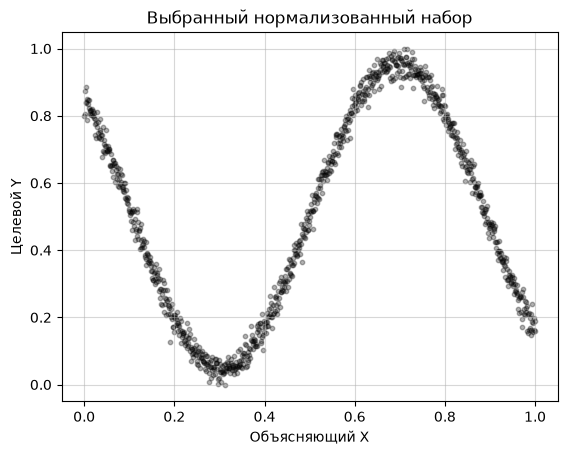

In [21]:
NormalizerX_EXAMPLE = MinMaxScaler().fit(x_train)
NormalizerY_EXAMPLE = MinMaxScaler().fit(y_train)
xNorm_train = NormalizerX_EXAMPLE.transform(x_train)
yNorm_train = NormalizerY_EXAMPLE.transform(y_train)

plt.scatter(xNorm_train, yNorm_train, s=markerSize, color="black", alpha=transparencyVal)
plt.title("Выбранный нормализованный набор")
plt.ylabel("Целевой Y"); plt.xlabel("Объясняющий X");
plt.grid(True, alpha=0.5)  # Сетка.

## Структура и параметры НС

Основным элементом искусственной нейронной сети (ИНС) является формальный нейрон. На выходе нейрона формируется итоговый сигнал "y" в зависимости от входных сигналов x0,…,xN. Значения входных сигналов могут усиливаться или ослабляться в зависимости от величины и знака весовых (передаточных) коэффициентов синапсов w0,…,wN.
Взвешенные сигналы суммируются и могут поступать на вход некоторой функции преобразователя - функции активации (передаточной функции). Функции активации могут иметь различный вид: линейный, либо разнообразный нелинейный.


Для решения задачи восстановления числовой зависимости (регрессии) будем использовать ИНС со структурой многослойный перцептрон (MLP, Multi Layer Perceptron). В такой структуре сигналы распространяются от входов к выходам и нейроны сгруппированы в слои. При этом соседние слои являются полносвязными, т.е. каждый нейрон из слоя-источника передает сигналы в каждый нейрон-слоя приемника.

Используя таблицу с образцами (определяющие Х и зависимый от них У), есть возможность сравнить вычисленные значения y_pred и ожидаемые (проверочные) y_test. Ошибки (разности) между вычисленными и ожидаемыми значениями передают в функцию оценки потерь (loss function) - функцию тем или иным способом вычисляющую единый коэфф. несоответствия.

Используя текущие значения потерь (loss), выбранная функция оптимизации  вычислит поправки к текущим весовым коэфф. w0,…,wN и применит их. Поправки вычисляются таким образом, чтобы минимизировать значения потерь (loss).

При подходе "обучение с учителем", нейронная сеть итеративно подбирает комбинацию весовых коэфф. такую, чтобы вычисленные ответы были как можно ближе к обучающим образцам.

Нейронная сеть для решения задачи регрессии должна содержать:
- Входной слой `Input` с размером, равным количеству передаваемых аргументов Х;
- Один или более скрытых полносвязных слоёв `Dense`
- Выходной слой `Dense`, число нейронов которого равно числу желаемых ответов У. Выходной слой должен передавать ответ без изменений, т.е. не иметь функции активации

Различные типы слоёв в пакете `tensorflow.keras.layers` имеют множество параметров для настройки. В данной работе будут использованы следующие:

- Input: входной слой, не изменяет проходящие значения. Содержит параметр
  - shape=(x) - определяющий размерность входной матрицы
- Dense: полносвязный слой, получает информацию со всех узлов предыдущего слоя. Содержит параметры:
  - units - кол-во узлов;
  - activation - выбор встроенной функции активации ;
- Activation: обособленный слой с выбранной функцией активации.

Полный список типов слоёв смотрите на странице справки
https://www.tensorflow.org/api_docs/python/tf/keras/layers

Обратите внимание, что допустимо задавать функции активации (ФА) несколькими способами:
1. "Явный", при котором ФА определена в самостоятельном слое и распологается сразу после полносвязного слоя `Dense`. Пример:
    ```
    model.add( layers.Dense     (  units= 1, activation= None ) )
    model.add( layers.Activation(  activation= tf.keras.activations.relu ) )
    ```
2. "Компактный", при котором желаема ФА передается в виде параметра `activation` объекта `Dense`
    ```
    model.add(  layers.Dense    (  units= 1,  activation= tf.keras.activations.relu ) )
    ```
Код в приведённых выше примерах приводит к одному и тому же итоговому состоянию сети.

* Структура нейронной сети:
  - кол-во входных нейронов = кол-ву "x"
  - кол-во скрытых полносвязных слоев
  - кол-во нейронов на каждом скрытом слое
  - типы функций активации после каждого слоя
  - кол-во выходных нейронов = кол-ву "y"

* Функции активации для скрытых слоев в пакете `tensorflow.keras.activation`. Некоторые доступные функции активации нейронов:
    - None - отсутсвие функции активации, означает передачу сигнала без изменений
    - relu
    - sigmoid:  sigmoid(x) = 1 / (1 + exp(-x))
    - tanh
    - linear
    - elu
    - Полный список функций активации смотрите на странице справке https://www.tensorflow.org/api_docs/python/tf/keras/activations



* Функция оценки потерь (способ оценки ошибок между y_pred и y), она же носит название Loss function Для задачи регрессии подходит оценка Среднеквадратичной ошибки (MSE) `tf.keras.losses.MeanSquaredError()`

    Доступные функции оценки потерь смотрите на странице справки https://www.tensorflow.org/api_docs/python/tf/keras/losses


* Функция оптимизации потерь/ошибок, т.е. поиска коэффициентов, при которых потери/ошибки будут минимальны. В качестве такой функции вы можете выбрать `Adam` или `SGD` (Стохастический градиентный спуск)

    Доступные функции оптимизации смотрите на странице справки https://www.tensorflow.org/api_docs/python/tf/keras/optimizers

Для создания нейросети в библиотеке Tensorflow необходимо создать объект tensorflow.keras.models.Sequential, который будет содержать последовательность отдельных слоёв (layers). Этот класс содержит множество методов, некоторые из них:
- add(layer) - добавить слой
- compile(loss, optimizer) - проверить и подготовить к обучению, задать функцию оценки потерь и функцию оптимизации потерь
- summary - сводная инф-ия
- fit(X, Y, epoch) - обучить
- predict (X) - вычислить ответы
- save - сохранить модель в файл
- load_weights/save_weights

Полный список функции и их параметров см. на странице справки https://www.tensorflow.org/api_docs/python/tf/keras/Sequential

Учитывая выбранные выше параметры, составим код для создания НС.

Заполните пропущенные параметры, при необходимости добавьте дополнительные слои. При этом рекомендуется:
- Использовать как минимум один скрытый слой с количеством узлов > 30 шт. и нелинейной функцией активации

Обратите внимание на то, что для решения задачи регрессии выходной слой не должен иметь нелинейной функции активации.

In [23]:
totalHistoryDict   = dict() # Вспомогательный словарь для хранения  для хранение полной истории обучения - списков значений метрик
globalEpochCounter = 0      # Общий счётчик выполненных эпох
trainSnapshots     = []     # Снимки ответов НС по ходу обучения (для итоговой анимации)

###########################################
#▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼

# 2.1) Построение модели нейронной сети многослойного(Sequential) типа ============================
# Многослойная
model = tf.keras.models.Sequential()

# ДОБАВЛЕНИЕ НОВЫХ СЛОЁВ
# Входной слой  -------------------------------------------------------------------------------
model.add( tf.keras.layers.Input(shape=(1,))) # Входной слой


# Скрытые слои --------------------------------------------------------------------------------
#   параметр "units" - кол-во узлов/нейронов на данном слое
#   параметр "activation" - вид функции активации
model.add(tf.keras.layers.Dense(units=100,  activation=None,        )) # Скрытй слой, полносвязный, без встроенной нелинейной функции активации
model.add(tf.keras.layers.Activation( activation=tf.keras.activations.relu,        )) # Обособленный слой с выбранной нелинейной функцией активации


# Дополнительные скрытые слои
model.add(tf.keras.layers.Dense(units=10,  activation=None,        ))
model.add(tf.keras.layers.Activation( activation=tf.keras.activations.relu,        ))

# Выходной полносвязный слой, Без нелинейной функции активации --------------------------------
model.add(tf.keras.layers.Dense(units=1,  activation=None))


# 3) Сборка и подготовка модели НС ===============================================================
model.compile(
    # Функции потерь и функции оптимизации
    loss      =tf.keras.losses.MeanSquaredError(), # Выбор функции оценки ошибок/потерь
    optimizer =tf.keras.optimizers.Adam(learning_rate=0.01), #  Выбор функции для минимзации значения выбранной оценки потерь. Adam/SGD
    #metrics   = [tf.keras.losses.MeanSquaredError(), tf.keras.losses.MeanAbsoluteError()] # Дополнительные метрики для оценки ошибок/потерь
)
#▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲
###########################################

print(model.summary())

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                      │ (None, 100)                 │             200 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation (Activation)              │ (None, 100)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │           1,010 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_1 (Activation)            │ (None, 10)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              11 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,221 (4.77 KB)

 Trainable params: 1,221 (4.77 KB)

 Non-trainable params: 0 (0.00 B)

None


## Первичное и дополнительное обучение

В процессе обучения будем получать вычисленные значения целевой переменной и строить график функции, соответствующий  текущему состоянию нейронной сети. Примеры изменения графиков представлены ниже.

Далее следует выполнить несколько циклов обучения (подстройки коэфф. каждого узла-нейрона) модели. Осмотрите результаты обучения, при необходимости выполните код нижестоящей ячейки повторно, при этом произойдёт дообучение нейросети. На графике также обратите внимание на численное значение выбранной функции оценки потерь (в примере используется fLoss =tf.keras.losses.mse).

_\*Для наглядности демонстрации процесса обучения и для возможности построения графика функции соответствующей текущему состоянию нейросети, количество эпох вынесено в цикл FOR, а соответствующий параметр epochs в метода fit установлен в "1"._


_\*В случае, если при работе на локальном JupyterLab вместо графиков отображается надпись "Loading widget..." , попробуйте обновить страницу браузера (F5), это связано с врЕменными особеностями менеджер виджетов в браузере._


True


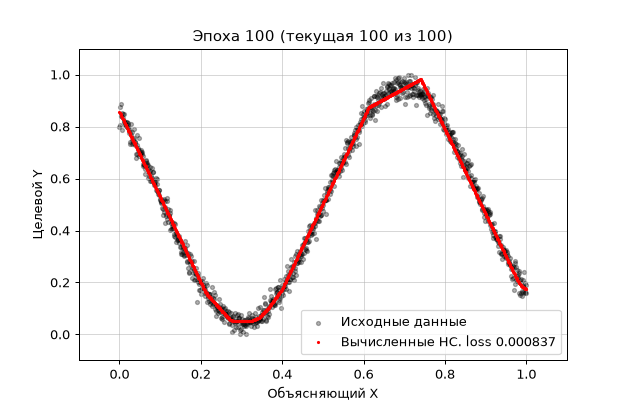

Эпоха    99 (текущая 100 из 100) | loss: 0.000837

In [25]:
# ── Обучающая ячейка (можно запускать многократно) ──────────────────────────────────────────
epochForTrainInRound = 100   # кол-во эпох в текущем запуске ячейки
plotEveryN  = 2             # обновлять график и сохранять снимок каждые N эпох
singleEpoch = 1
# ── Вспомогательный блок для отображения графика функции для единстенного "x"  ──────────────
isDrawable = xNorm_train.shape[1] == 1   # график "x -> y" возможен только при одном входе
print(isDrawable)
if isDrawable:
    figLive, predLine, liveHandle = createLivePlot(xNorm_train, yNorm_train)
    yNorm_pred = model.predict(xNorm_train, verbose=0)
    updateLivePlot(figLive, predLine, liveHandle, yNorm_pred, f"Эпоха {globalEpochCounter} (перед запуском)")
    if not trainSnapshots:   # начальное (необученное) состояние сохраняем один раз
        trainSnapshots.append({'epoch': globalEpochCounter, 'y': yNorm_pred.ravel(), 'loss': np.nan})

# ── Цикл обучения ─────────────────────────────────────────
# 3) Очередной круг ногово или продолжения обучения сети (выполнить epochForTrainInRound итераций по метод по 1 эпохе)
for currEpochNum in range(1, epochForTrainInRound + 1):
    #▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼
    # Непосредственно обучение. Вызов метода fit для настройки коэфф. нейросети
    history = model.fit(
        xNorm_train, yNorm_train, # Обучающие X и Y
        #validation_data=(xNorm_test, yNorm_test), # Опционально проверочные X и Y, для вычисления оценок потерь (loss)
        epochs=singleEpoch,       # Кол-во эпох обучения (в текущей ячейке должно быть равным 1)
        batch_size=200, # Внутри каждой эпохи, проводить обучение пакетами/порциями по batch_size строк
        verbose=0, callbacks=[logShortener],   )
    #▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲
    globalEpochCounter += singleEpoch   # сразу после fit, чтобы заголовок не отставал

    # Сбор и дополнение полной истории обучения
    for key, vals in history.history.items():
        totalHistoryDict.setdefault(key, []).extend(vals)

    #  Каждые N эпох выводить график текущей функции НС. Только в условиях ЕДИНСТВЕННОГО x.
    if isDrawable and (currEpochNum % plotEveryN == 0 or currEpochNum == epochForTrainInRound):
        yNorm_pred = model.predict(xNorm_train, verbose=0)
        loss = history.history['loss'][-1]
        trainSnapshots.append({'epoch': globalEpochCounter, 'y': yNorm_pred.ravel(), 'loss': loss})
        updateLivePlot(figLive, predLine, liveHandle, yNorm_pred,
                       f"Эпоха {globalEpochCounter} (текущая {currEpochNum} из {epochForTrainInRound})", loss)

Осмотрим ещё раз изменения графика функции в процессе обучения

In [26]:
# Анимация по всем накопленным снимкам (после завершения обучения нажмите ▶ Play)
print(f"Накоплено снимков: {len(trainSnapshots)}")
showTrainingAnimation(xNorm_train, yNorm_train, trainSnapshots)

Накоплено снимков: 51


 В процессе обучения, НС на каждой эпохе измеряет и фиксирует значения ошибок/потерь (loss) с помощью выбранной функции. После выполнения метод `fit` возвращает объект `history` в котором можно получить доступ списку значениям этих ошибок, но только по тем эпохам, которые были выполнены в последнем вызове метода `fit`. В вышестоящей ячейке значения из `history` переносится в `totalHistoryDict['loss']` и `totalHistoryDict['val_loss']` для получения полной истории для результотов на обучающей и проверочной частях соотвественно, начиная с первой эпохи.

## Оценка точности

Отобразим изменения значений потерь/ошибок по эпохам в виде графика. По виду этого графика вы можете оценить степень обученности НС.

Доступные метрики полной истории обучения: dict_keys(['loss'])


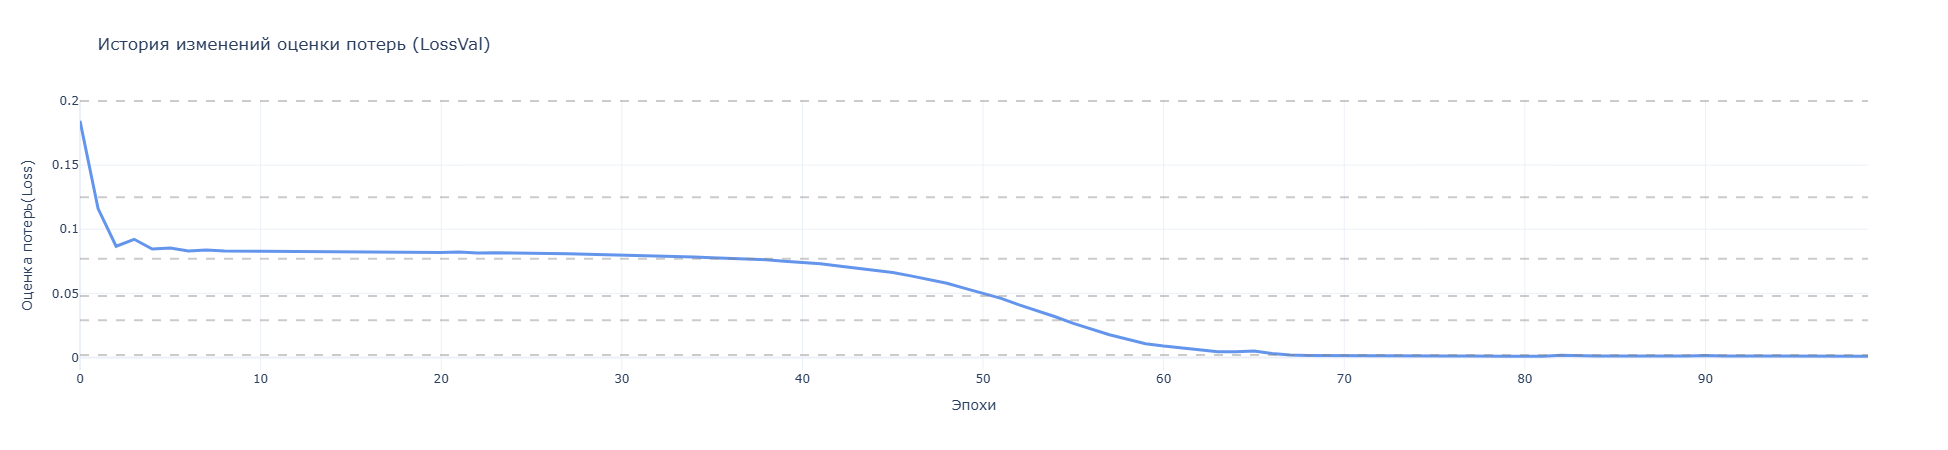

In [27]:
# Отобразить график изменения оценки потерь по эпохам обучения
print('Доступные метрики полной истории обучения:', totalHistoryDict.keys())
fig = go.Figure()
fig.add_trace(go.Scatter( y=totalHistoryDict['loss'], mode="lines", name="Обучающая (loss)", line=dict(width=3, color='cornflowerblue')))
if 'val_loss' in totalHistoryDict.keys():
    fig.add_trace(go.Scatter( y=totalHistoryDict['val_loss'],  mode="lines", name="Проверочная (val_loss)",     line=dict(width=3, color='darkorange')))

refHFib = np.array([13, 8, 5, 3, 2, 1, 0.8, 0.5, 0.33, 0.2, 0.125, 0.077, 0.048,  0.029, 0.0018])
m2 = refHFib<=np.max(totalHistoryDict['loss'])
m2 = np.concatenate([m2[1:], [True]*1])
for y in refHFib[m2]:# Горизонтальные опорные линии (порядки величин)
    fig.add_hline(y=y, line_dash="dash", line_color="gray", opacity=0.4)

# Настройки осей
fig.update_xaxes(title="Эпохи"); fig.update_yaxes(title="Оценка потерь(Loss)") # type="log",
fig.update_layout(title="История изменений оценки потерь (LossVal)", template="plotly_white",
                  width=900, height=450, legend=dict(yanchor="top", x=0.4, y=1.0))
fig.show()

In [28]:
# Осмотрим последние значения выбранной оценки потерь (LossVal = mean_squared_error)
print (totalHistoryDict['loss'][-5:])

[0.0009211398428305984, 0.0008424954139627516, 0.000800273206550628, 0.000718533294275403, 0.0008365126559510827]



В редких случаях в ходе продолжительного обучения при недостаточной степени обучения, возможно потребуется проинициализировать НС новыми случайными весовыми коэфф. и начать обучение заново.

<font color='red'>
Внимание! Для сокращения кода, обучение НС и оценка точности проводится на одном и том же ОБУЧАЮЩЕМ наборе данных xNorm_train, что не отображает реальное обобщающее свойство модели. При выполнении в дальнейшем основной части вам необходимо проводить оценку точности на ПРОВЕРОЧНОЙ части xNorm_test.
</font>

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
MAE :     0.021 (средняя абсолютная ошибка)
MSE :  0.000705 (среднеквадратичная ошибка)
RMSE:  0.026552 (кв. корень из среднеквадратичной ошибки)
R2  :     0.992 (коэфф. детерминации)


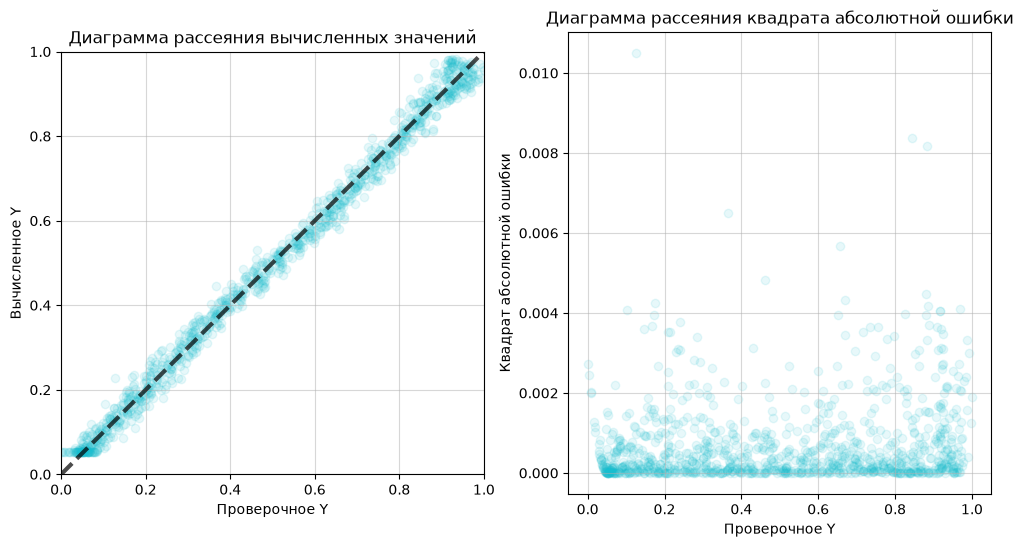

In [29]:
# Вычислить ответы НС
yNorm_pred = model.predict(  xNorm_train  ) # В базовом примере используется проверка на ОБУЧАЮЩЕЙ ЧАСТИ, в дальшейшей работе необходимо проводить проверку на ПРОВЕРОЧНОЙ ЧАСТИ

GET_METRICS_SINGLE(yNorm_train, yNorm_pred)
PLOT34(yNorm_train, yNorm_pred)

# Загрузка данных по личному варинату

## Загрузка данных и дополнительная очистка выбросов

Файл `SeoulBikeData_prepared.csv` — результат ЛР1. Следующая ячейка удаляет выбросы по IQR и сохраняет `SeoulBikeData_prepared_no_outliers.csv` (8 371 строка). Оба CSV находятся рядом с ноутбуком.

In [33]:
df = pd.read_csv('./SeoulBikeData_prepared.csv')

print("Размер таблицы:", df.shape)
df.head()

Размер таблицы: (8756, 20)


,Rented Bike Count,Hour,Temperature(°K),Wind speed (m-s),Humidity(%),Visibility (10m),Dew point temperature(°K),Solar Radiation (MJ-m2),Rainfall(mm),Snowfall (cm),Date_month,Date_dayofweek,Seas_Autumn,Seas_Spring,Seas_Summer,Seas_Winter,Hold_Holiday,Hold_No Holiday,Fday_No,Fday_Yes
0,254,0,267.95,2.2,37.0,2000.0,255.55,0.0,0.0,0.0,12,4,0,0,0,1,0,1,0,1
1,204,1,267.65,0.8,38.0,2000.0,255.55,0.0,0.0,0.0,12,4,0,0,0,1,0,1,0,1
2,173,2,267.15,1.0,39.0,2000.0,255.45,0.0,0.0,0.0,12,4,0,0,0,1,0,1,0,1
3,107,3,266.95,0.9,40.0,2000.0,255.55,0.0,0.0,0.0,12,4,0,0,0,1,0,1,0,1
4,78,4,267.15,2.3,36.0,2000.0,254.55,0.0,0.0,0.0,12,4,0,0,0,1,0,1,0,1


In [34]:
print(df.columns.tolist())

['Rented Bike Count', 'Hour', 'Temperature(°K)', 'Wind speed (m-s)', 'Humidity(%)', 'Visibility (10m)', 'Dew point temperature(°K)', 'Solar Radiation (MJ-m2)', 'Rainfall(mm)', 'Snowfall (cm)', 'Date_month', 'Date_dayofweek', 'Seas_Autumn', 'Seas_Spring', 'Seas_Summer', 'Seas_Winter', 'Hold_Holiday', 'Hold_No Holiday', 'Fday_No', 'Fday_Yes']


# Удаление выбросов

In [39]:
df_original = pd.read_csv('./SeoulBikeData_prepared.csv')

regular_columns = [
    'Rented Bike Count',
    'Temperature(°K)',
    'Humidity(%)',
    'Wind speed (m-s)',
    'Visibility (10m)',
    'Dew point temperature(°K)'
]

positive_columns = [
    'Solar Radiation (MJ-m2)',
    'Rainfall(mm)',
    'Snowfall (cm)'
]

mask = pd.Series(True, index=df_original.index)
report = []

for col in regular_columns:
    q1 = df_original[col].quantile(0.25)
    q3 = df_original[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    valid = df_original[col].between(lower, upper)
    mask &= valid

    report.append([col, round(lower, 3), round(upper, 3), (~valid).sum()])

for col in positive_columns:
    positive = df_original.loc[df_original[col] > 0, col]

    q1 = positive.quantile(0.25)
    q3 = positive.quantile(0.75)
    iqr = q3 - q1

    lower = max(0, q1 - 1.5 * iqr)
    upper = q3 + 1.5 * iqr

    valid = (df_original[col] == 0) | (
        (df_original[col] > 0) &
        df_original[col].between(lower, upper)
    )

    mask &= valid

    report.append([col, round(lower, 3), round(upper, 3), (~valid).sum()])

df = df_original.loc[mask].reset_index(drop=True)

report_df = pd.DataFrame(
    report,
    columns=['Признак', 'Нижняя граница', 'Верхняя граница', 'Выбросов']
)

print(report_df.to_string(index=False))

print('\nСтрок до очистки:', len(df_original))
print('Строк после очистки:', len(df))
print('Удалено строк:', len(df_original) - len(df))
print('Размер итоговой таблицы:', df.shape)
print('Осталось пропусков:', df.isna().sum().sum())

df.to_csv(
    './SeoulBikeData_prepared_no_outliers.csv',
    index=False,
    encoding='utf-8-sig'
)

                  Признак  Нижняя граница  Верхняя граница  Выбросов
        Rented Bike Count       -1118.500         2373.500       159
          Temperature(°K)         248.088          324.187         0
              Humidity(%)          -3.500          120.500         0
         Wind speed (m-s)          -1.200            4.400       161
         Visibility (10m)        -650.000         3590.000         0
Dew point temperature(°K)         239.200          317.200         0
  Solar Radiation (MJ-m2)           0.000            4.115         0
             Rainfall(mm)           0.000            5.500        57
            Snowfall (cm)           0.000            4.750        10

Строк до очистки: 8756
Строк после очистки: 8371
Удалено строк: 385
Размер итоговой таблицы: (8371, 20)
Осталось пропусков: 0


# Приведение к новой единой шкале. Нормализация

Некоторые методы машинного обучения чувствительны к тому, какой порядок величин имеют значения признаков.



- __Нормализация__  -  приведения значений к диапазону от 0.0 до 1.0 Пример:
      
      |--------------|+++++++++|----|
      |--------------|++++++++++++++|
      0             1900     1970  2000
      
      Обрабатываемое: 1970
      Макс. значение: 1900
      Мин. значение:  2000
      
      Процедура нормализации:
      x_norm = ( x - X.min() ) / ( X.max() -  X.min() )
      x_norm = ( 1970 - 1900 ) / (2000 - 1900)
      x_norm = 70 / 100
      x_norm = 0.70
      
      Восстановление:
      x = ( x_norm * ( X.max() -  X.min() ) +  X.min()
      x = ( 0.70 * (2000 - 1900) + 1900
      x = ( 0.70 * 100) + 1900
      x = 70 + 1900
      x = 1970

<div>

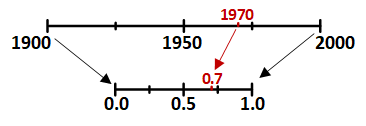
<p style="text-align: right;"> Рисунок. Вид диапазона значений до и после нормализации </p>
</div>


## Выделение X и Y

Для выполнения следующих шагов разделим исходную таблицу на две отдельных
  - dfX содержащую только объясняющие признаки
  - dfY содержащую только целевой объясняемый признак

In [40]:
df = pd.read_csv('./SeoulBikeData_prepared_no_outliers.csv')

In [41]:
features = ['Hour', 'Temperature(°K)', 'Rainfall(mm)',  'Wind speed (m-s)', 'Snowfall (cm)']
target   = ['Rented Bike Count']

In [42]:
dfX = df[features]
print("Размер таблицы", dfX.shape)
dfX[:2]

Размер таблицы (8371, 5)


,Hour,Temperature(°K),Rainfall(mm),Wind speed (m-s),Snowfall (cm)
0,0,267.95,0.0,2.2,0.0
1,1,267.65,0.0,0.8,0.0


In [43]:
dfY = df[target]
print("Размер таблицы", dfY.shape)
dfY[:2]

Размер таблицы (8371, 1)


,Rented Bike Count
0,254
1,204


## Использование класса MinMaxScaler

В библиотеке sklearn, для выполнения процедуры нормализации, присутствует более удобный класс __sklearn.preprocessing.MinMaxScaler__, который содержит методы:

- __MinMaxScaler.fit(  df  )__ - вычисление значений __минимального__, __максимального значений__ и __диапазона__

- __MinMaxScaler.transform( df )__ - прямого преобразования из истинного значения к приведенному

- __MinMaxScaler.inverse_transform( df )__ - обратного преобразования из приведенного значения в истинное

In [44]:
scalerNormX = MinMaxScaler()
scalerNormX.fit(dfX)

dfXNorm = pd.DataFrame (
  data    = scalerNormX.transform(dfX), # значения ячеек    <<--
  columns = dfX.columns,           # названия столбцов
  index   = dfX.index              # идентификаторы строк
)
print("Размер таблицы", dfXNorm.shape)
dfXNorm[:2]

Размер таблицы (8371, 5)


,Hour,Temperature(°K),Rainfall(mm),Wind speed (m-s),Snowfall (cm)
0,0.000000,0.220280,0.0,0.511628,0.0
1,0.043478,0.215035,0.0,0.186047,0.0


In [45]:
scalerNormY = MinMaxScaler()
scalerNormY.fit(dfY)

dfYNorm = pd.DataFrame (
  data    = scalerNormY.transform(dfY), # значения ячеек    <<--
  columns = dfY.columns,           # названия столбцов
  index   = dfY.index              # идентификаторы строк
)
print("Размер таблицы", dfYNorm.shape)
dfYNorm[:2]

Размер таблицы (8371, 1)


,Rented Bike Count
0,0.107083
1,0.086003


## Проверка нормализации

Осмотрим гистограммы по каждому признаку и проверим их мин. и макс. значения.

In [46]:
dfXNorm.describe().loc[["min", "max" ]]

,Hour,Temperature(°K),Rainfall(mm),Wind speed (m-s),Snowfall (cm)
min,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0


In [47]:
dfYNorm.describe().loc[["min", "max" ]]

,Rented Bike Count
min,0.0
max,1.0


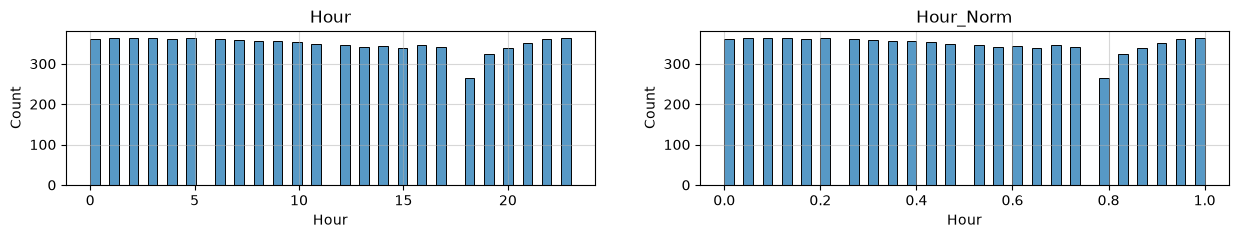

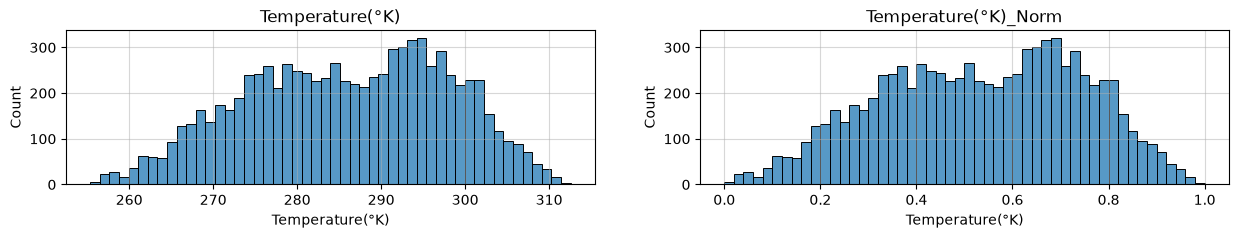

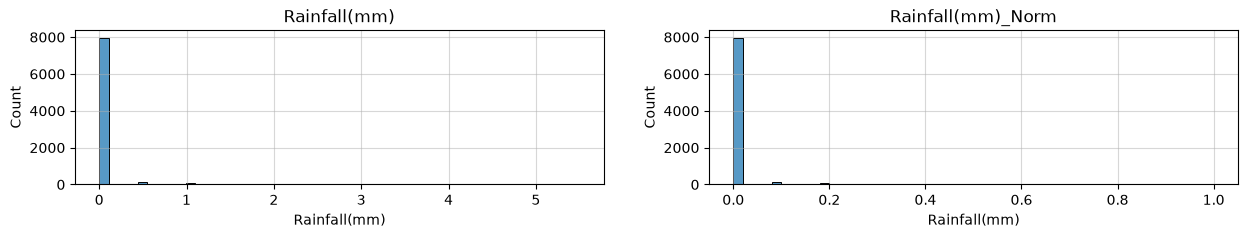

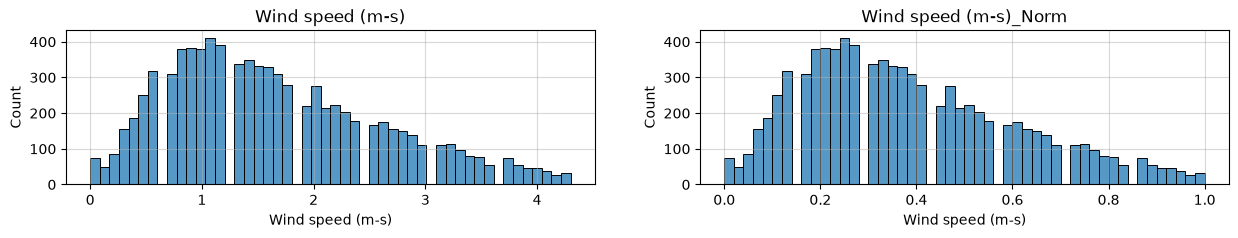

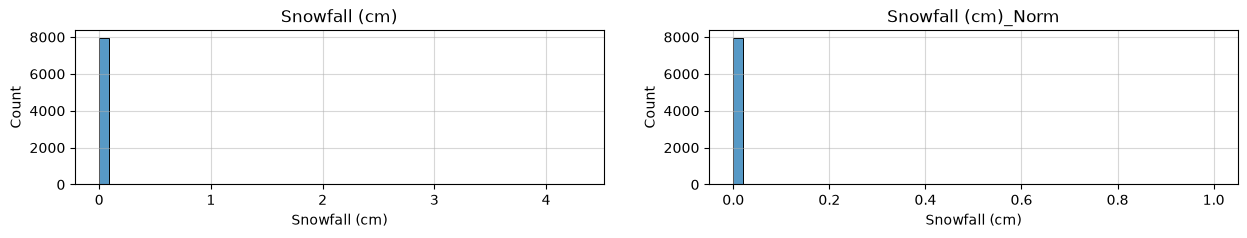

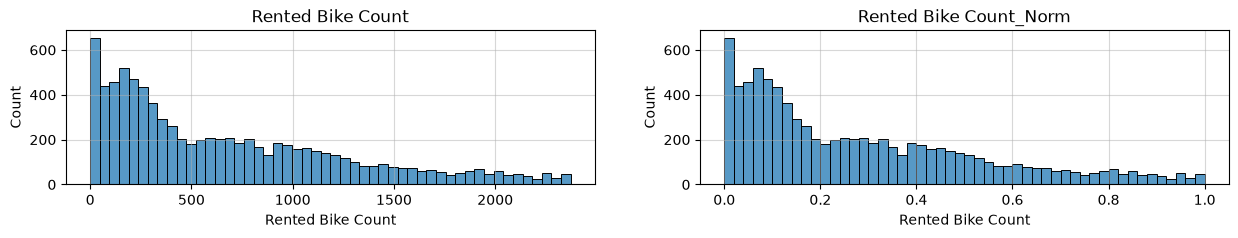

In [48]:
for dfN in [dfXNorm, dfYNorm]:
    for i, colName in enumerate(dfN.columns ):
        #if df[colName].dtype == 'bool': continue
        plt.figure(figsize=(15, 2))

        plt.subplot(1, 2, 1)
        sns.histplot(df[colName], bins=50)
        plt.title(colName)
        plt.grid(True, alpha=0.5) # Сетка.

        plt.subplot(1, 2, 2)
        sns.histplot(dfN[colName], bins=50)
        plt.title(colName+"_Norm")
        plt.grid(True, alpha=0.5)  # Сетка.

# Формирование тренировочной и проверочной выборок

In [49]:
valid_size = 0.3 # доля тестовой части в выборке
rand_seed = 8 # начальное состояние генератора случ. чисел

## Нормализованые

In [50]:
xNorm_train, xNorm_test, yNorm_train, yNorm_test =  train_test_split(
    dfXNorm[features], # исходные данные X
    dfYNorm[target],   # исходные данные y

    test_size    = valid_size, # доля тестовой части в выборке
    random_state =rand_seed,   # начальное состояние генератора случ. чисел
    shuffle=True               # перемешивание
)

In [51]:
xNorm_train[:2]

,Hour,Temperature(°K),Rainfall(mm),Wind speed (m-s),Snowfall (cm)
6965,0.652174,0.643357,0.000000,0.883721,0.0
4864,0.826087,0.732517,0.272727,0.488372,0.0


In [52]:
yNorm_train[:2]

,Rented Bike Count
6965,0.530354
4864,0.018550


# Нейронная сеть m1. Построение модели без скрытых слоев от ДВУХ "x" (2_вх->1_вых)

## Структура и параметры

Дополните код для построения НС со структурой `2вх->1вых`, следовательно:
- входной слой должен принимать 2 значения
- скрытые слои отсутствуют
- выходной слой вычисляет единственное значение и не имеет функцию активации

In [53]:
totalHistoryDict   = dict() # Вспомогательный словарь для хранения  для хранение полной истории обучения - списков значений метрик
globalEpochCounter = 0      # Общий счётчик эпох

###########################################
#▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼▼
# 1) Параметры структуры

# 2.1) Построение модели нейронной сети многослойного(Sequential) типа ============================
model = tf.keras.models.Sequential()

# Входной слой ------------------------------------------------------------------------------------
model.add(   tf.keras.layers.Input( shape=(  2 ,  ) # пример: shape=(1,)
))

# Скрытые слои ------------------------------------------------------------------------------------
#   параметр "units" - кол-во узлов/нейронов на данном слое
#   параметр "activation" - вид функции активации

# Скрытй слой, полносвязный, без встроенной нелинейной функции активации
#model.add(   tf.keras.layers.Dense(    units     = >>> Задайте_кол-во_узлов_выходного_слоя <<<    ,    activation=None,))
#  Обособленный слой с выбранной нелинейной функцией активации
#model.add(   tf.keras.layers.Activation(  activation = tf.keras.activations.>>>Выберите_вид_функции_активации<<<, ))

# Дополнительные скрытые слои ...

# Выходной полносвязный слой, Без нелинейной функции активации -------------------------------------
# Кол-во нейронов на последнем слое опредеяет кол-во выходных значений нейронной сети
model.add(    tf.keras.layers.Dense(units=1,  activation=None))


# 3) Сборка и подготовка модели НС ===================================================================
model.compile(
    # Функции оценки потерь, функции оптимизации, метрики
    loss      = tf.keras.losses.MeanSquaredError(), # Выбор функции оценки ошибок/потерь
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.01) # SGD(learning_rate=0.01) или  Adam(learning_rate=0.01), # Выбор функции для минимзации значения выбранной оценки ошибок/потерь
    #metrics  = [tf.keras.losses.MeanSquaredError(), tf.keras.losses.MeanAbsoluteError()] # Дополнительные метрики для оценки ошибок/потерь
)
#▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲▲
###########################################

print("Вывод краткой информации о структуре НС")
print(model.summary())

Вывод краткой информации о структуре НС


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                      │ (None, 1)                   │               3 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3 (12.00 B)

 Trainable params: 3 (12.00 B)

 Non-trainable params: 0 (0.00 B)

None


## Первичное и дополнительное обучение

In [54]:
xNorm_train.columns

Index(['Hour', 'Temperature(°K)', 'Rainfall(mm)', 'Wind speed (m-s)',
       'Snowfall (cm)'],
      dtype='str')

In [55]:
# Осмотрим используемые для обучения столбцы исходной таблицы
xNorm_train [["Hour", "Temperature(°K)", ]]

,Hour,Temperature(°K)
6965,0.652174,0.643357
4864,0.826087,0.732517
6323,0.347826,0.734266
5799,0.782609,0.912587
3845,0.956522,0.694056
...,...,...
5480,0.434783,0.877622
6995,0.956522,0.582168
2181,0.521739,0.444056
2033,0.869565,0.386364


In [56]:
# Осмотрим используемые для обучения столбцы исходной таблицы
yNorm_train

,Rented Bike Count
6965,0.530354
4864,0.018550
6323,0.666105
5799,0.537099
3845,0.168212
...,...
5480,0.199410
6995,0.000000
2181,0.184654
2033,0.203626


In [57]:
# 4) Обучение/продолжение обучения сети
epochForTrain = 100

# Вызов метода для выполнения обучения (настройки коэфф. нейросети)
history = model.fit(
    xNorm_train[["Hour", "Temperature(°K)"]],  # обучающие X  # требуется передать таблицу с кол-ом столбцов равным кол-ву входных нейронов
    yNorm_train,  # обучающие Y
    validation_data=(  # опционально: проверочные X и Y
        xNorm_test[["Hour", "Temperature(°K)"]],  # требуется передать таблицу с кол-вом столбцов равным кол-ву входных нейронов
        yNorm_test),
    epochs=epochForTrain,   # кол-во эпох обучения
    #batch_size=100, # внутри каждой эпохи, проводить обучение пакетами/порциями по batch_size строк
    verbose=0,
)

# Сбор и дополнение полной истории обучения
for key in history.history.keys():
    if key not in totalHistoryDict.keys(): totalHistoryDict[key]=list()
    totalHistoryDict[key].extend(history.history[key])

## Оценка точности

Доступные метрики полной истории обучения: dict_keys(['loss', 'val_loss'])


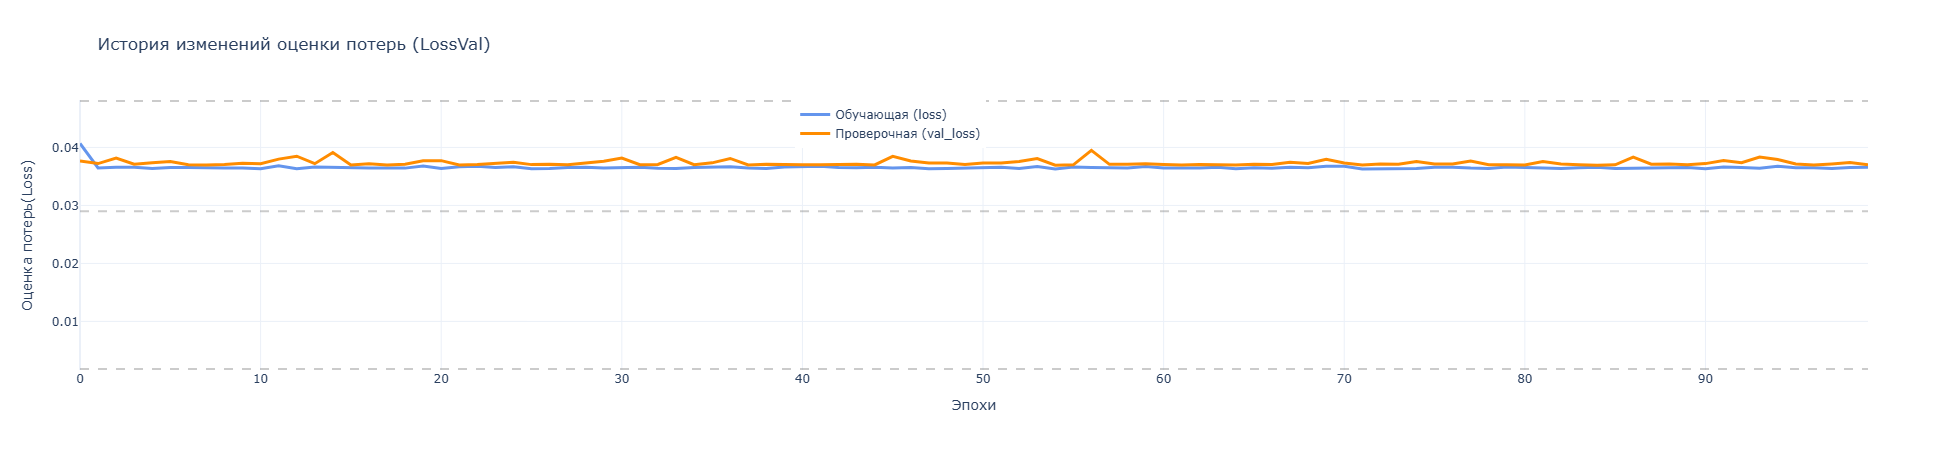

In [58]:
# Отобразить график изменения оценки потерь по эпохам обучения
print('Доступные метрики полной истории обучения:', totalHistoryDict.keys())
fig = go.Figure()
fig.add_trace(go.Scatter( y=totalHistoryDict['loss'], mode="lines", name="Обучающая (loss)", line=dict(width=3, color='cornflowerblue')))
if 'val_loss' in totalHistoryDict.keys():
    fig.add_trace(go.Scatter( y=totalHistoryDict['val_loss'],  mode="lines", name="Проверочная (val_loss)",     line=dict(width=3, color='darkorange')))

refHFib = np.array([13, 8, 5, 3, 2, 1, 0.8, 0.5, 0.33, 0.2, 0.125, 0.077, 0.048,  0.029, 0.0018])
m2 = refHFib<=np.max(totalHistoryDict['loss'])
m2 = np.concatenate([m2[1:], [True]*1])
for y in refHFib[m2]:# Горизонтальные опорные линии (порядки величин)
    fig.add_hline(y=y, line_dash="dash", line_color="gray", opacity=0.4)

# Настройки осей
fig.update_xaxes(title="Эпохи"); fig.update_yaxes(title="Оценка потерь(Loss)") # type="log",
fig.update_layout(title="История изменений оценки потерь (LossVal)", template="plotly_white",
                  width=900, height=450, legend=dict(yanchor="top", x=0.4, y=1.0))
fig.show()

In [59]:
# Осмотрим последние значения выбраной оценки потерь (LossVal = mean_squared_error)
totalHistoryDict['val_loss'][-5:]

[0.037157535552978516,
 0.03696227818727493,
 0.03715691715478897,
 0.03741060942411423,
 0.037029922008514404]

In [62]:
# Вычислить ответы НС на ПРОВЕРОЧНОЙ ЧАСТИ
yNorm_pred = model.predict( xNorm_test [["Hour", "Temperature(°K)",]] ) # требуется передать таблицу с кол-вом столбцов равным кол-ву входных нейронов

# Вычислить метрики и построить графики, сравнивая ответы НС с ПРОВЕРОЧНОЙ ЧАСТЬЮ
GET_METRICS_SINGLE(yNorm_test, yNorm_pred) # Вычислить метрики точности
PLOT34(yNorm_test, yNorm_pred)   # Отобразить графики для вычисленных значений

79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
MAE :     0.145 (средняя абсолютная ошибка)
MSE :  0.037030 (среднеквадратичная ошибка)
RMSE:  0.192432 (кв. корень из среднеквадратичной ошибки)
R2  :     0.413 (коэфф. детерминации)


Осмотрим вычисленные значения, учитывайте, что нейросеть формирует ответы в той же шкале что и была задана при обучении, т.е. в нормализованной шкале Y.

## Получение весовых коэфф. w_i и bias для модели m1 (2_вх->1_вых)

Осмотрите параметры и значения весовых коэфф. каждого отдельного слоя.

Обратите внимание на следующее:
- количество элементов списка и то, что входной слой Input явно не выделен в самостоятельный слой, а определяет входные параметры следующего за ним слоя;
- при каждом создании новой нейронной сети значения весовых коэфф. (связей между нейронами) отличается от нулевых и назначается генератором случайных чисел;
- слой с нелинейной функцией активации не имеет коэфф.



In [63]:
printModelWeights(model)

####################################################################################################
#### Имя слоя:dense_4;  Тип слоя: <class 'keras.src.layers.core.dense.Dense'> ##########
Вид ф-ии активации слоя: linear
Кол-во ВХодов  слоя: 2
Кол-во ВЫХодов слоя: 1
Кол-во нейронов слоя:    1

Весовые коэфф. weight_i_j=
[[0.28441787]
 [0.6005947 ]]

Весовые коэфф. bias_i_j=
[-0.18450625]




## Построение 3d графика зависимости вычисленных значений Y_pred от объясняющих признаков x1 и x2

In [64]:
dfX.columns

Index(['Hour', 'Temperature(°K)', 'Rainfall(mm)', 'Wind speed (m-s)',
       'Snowfall (cm)'],
      dtype='str')

In [65]:
my3dplot(
    xNorm_train, yNorm_train,  True, # Обучающие x и y, Флаг отображения обучающих точек  (синие)
    xNorm_test,  yNorm_test,   True, # Проверочные x и y, Флаг отображения проверочных точек   (оранжевые)
    yNorm_pred,                True, # Вычисленные y, Флаг отображения вычисленной функции  (зелёные)
    x1Name= "Hour",  x2Name="Temperature(°K)", y_targetName= target[0], # Имена столбцов из таблиц  xNorm_train, xNorm_test, yNorm_pred
    pointSize = 5,     # Размер точки
    pointTransparency  = 0.4, # Прозрачность точек графика train, test
    meshTransparency   = 0.3  # Прозрачность поверхности вычисленных значений y_pred
)

# Нейронная сеть m2. Построение модели со скрытыми слоями от ДВУХ "x" (2_вх-> ??? -> ??? ->1_вых)

In [82]:
totalHistoryDict2   = dict()
globalEpochCounter = 0


model2 = tf.keras.models.Sequential()

model2.add(   tf.keras.layers.Input( shape=(  2 ,  )
))


model2.add(   tf.keras.layers.Dense(    units     = 64    ,    activation=None,))
model2.add(   tf.keras.layers.Activation(  activation = tf.keras.activations.relu, ))

model2.add(   tf.keras.layers.Dense(    units     = 32    ,    activation=None,))

model2.add(   tf.keras.layers.Activation(  activation = tf.keras.activations.relu, ))

model2.add(    tf.keras.layers.Dense(units=1,  activation=None))


model2.compile(
    loss      = tf.keras.losses.MeanSquaredError(),
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.01)
)

print("Вывод краткой информации о структуре НС")
print(model2.summary())

Вывод краткой информации о структуре НС


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                     │ (None, 64)                  │             192 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_6 (Activation)            │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_13 (Dense)                     │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_7 (Activation)            │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_14 (Dense)                     │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,305 (9.00 KB)

 Trainable params: 2,305 (9.00 KB)

 Non-trainable params: 0 (0.00 B)

None


In [83]:
epochForTrain = 100

history = model2.fit(
    xNorm_train[["Hour", "Temperature(°K)"]],
    yNorm_train,
    validation_data=(
        xNorm_test[["Hour", "Temperature(°K)"]],
        yNorm_test),
    epochs=epochForTrain,
    verbose=0,
)

for key in history.history.keys():
    if key not in totalHistoryDict2.keys(): totalHistoryDict2[key]=list()
    totalHistoryDict2[key].extend(history.history[key])

Доступные метрики полной истории обучения: dict_keys(['loss', 'val_loss'])


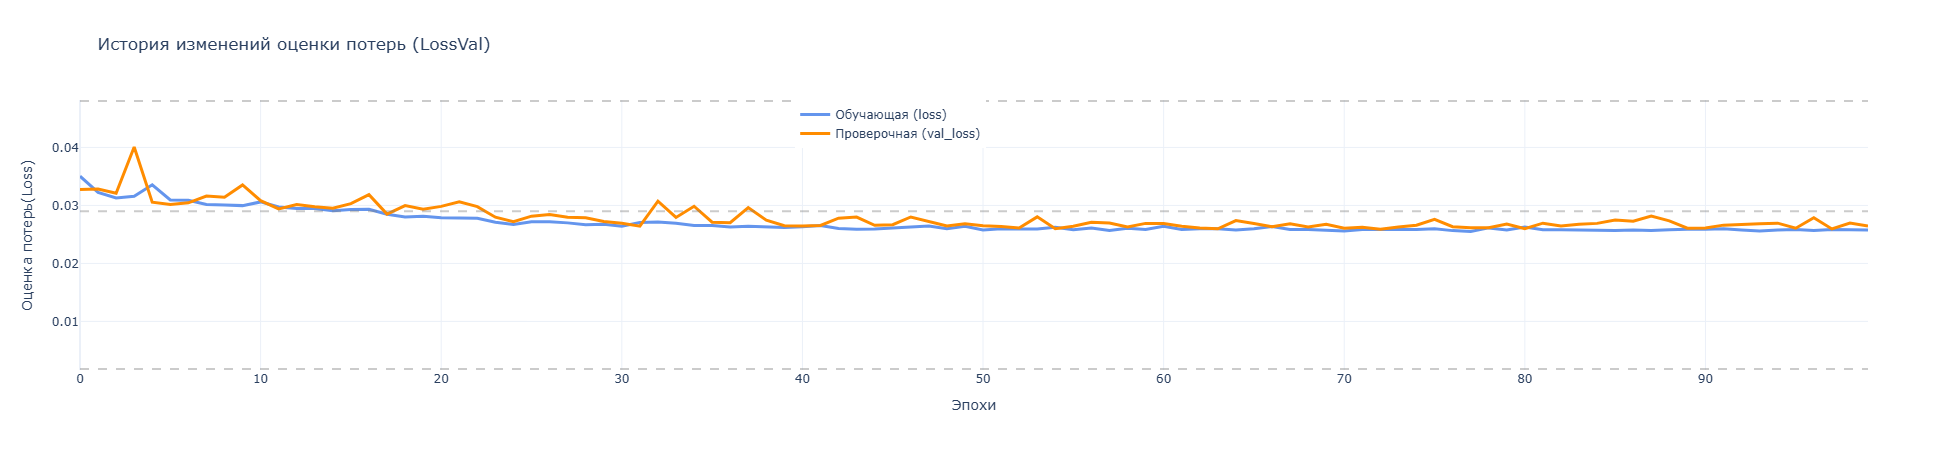

In [84]:
print('Доступные метрики полной истории обучения:', totalHistoryDict2.keys())
fig = go.Figure()
fig.add_trace(go.Scatter( y=totalHistoryDict2['loss'], mode="lines", name="Обучающая (loss)", line=dict(width=3, color='cornflowerblue')))
if 'val_loss' in totalHistoryDict2.keys():
    fig.add_trace(go.Scatter( y=totalHistoryDict2['val_loss'],  mode="lines", name="Проверочная (val_loss)",     line=dict(width=3, color='darkorange')))

refHFib = np.array([13, 8, 5, 3, 2, 1, 0.8, 0.5, 0.33, 0.2, 0.125, 0.077, 0.048,  0.029, 0.0018])
m2 = refHFib<=np.max(totalHistoryDict2['loss'])
m2 = np.concatenate([m2[1:], [True]*1])
for y in refHFib[m2]:
    fig.add_hline(y=y, line_dash="dash", line_color="gray", opacity=0.4)

fig.update_xaxes(title="Эпохи"); fig.update_yaxes(title="Оценка потерь(Loss)")
fig.update_layout(title="История изменений оценки потерь (LossVal)", template="plotly_white",
                  width=900, height=450, legend=dict(yanchor="top", x=0.4, y=1.0))
fig.show()

In [85]:
totalHistoryDict2['val_loss'][-5:]

yNorm_pred = model2.predict( xNorm_test [["Hour", "Temperature(°K)",]] )

GET_METRICS_SINGLE(yNorm_test, yNorm_pred)
PLOT34(yNorm_test, yNorm_pred)

79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
MAE :     0.107 (средняя абсолютная ошибка)
MSE :  0.026454 (среднеквадратичная ошибка)
RMSE:  0.162647 (кв. корень из среднеквадратичной ошибки)
R2  :     0.581 (коэфф. детерминации)


In [86]:
printModelWeights(model2)

####################################################################################################
#### Имя слоя:dense_12;  Тип слоя: <class 'keras.src.layers.core.dense.Dense'> ##########
Вид ф-ии активации слоя: linear
Кол-во ВХодов  слоя: 2
Кол-во ВЫХодов слоя: 64
Кол-во нейронов слоя:    64

Весовые коэфф. weight_i_j=
[[-1.02841347e-01  4.00152892e-01  2.98233181e-02  1.09583132e-01
   1.99200675e-01 -1.47917494e-01 -1.54726863e-01 -4.83398139e-02
   4.42386180e-01 -1.24843214e-02 -2.69397557e-01  1.68809772e-01
  -2.50367731e-01 -2.11839005e-01 -2.66864300e-01 -2.45360762e-01
  -2.00720757e-01 -2.38413643e-03 -1.07465759e-01  1.43840894e-01
  -7.49970317e-01 -3.13150398e-02  4.84190494e-01  1.10397369e-01
  -2.20846385e-01 -1.08385980e-02  4.01349878e-03 -1.81253061e-01
  -1.25796527e-01 -1.61283588e+00  6.04484417e-02  1.15963006e+00
  -3.57468081e+00 -1.15267634e+00  3.38520668e-02 -2.91384482e+00
   2.00478323e-02 -1.34263679e-01  3.17247882e-02  2.90367484e-01
  -2.44319960e

In [87]:
my3dplot(
    xNorm_train, yNorm_train,  True,
    xNorm_test,  yNorm_test,   True,
    yNorm_pred,                True,
    x1Name= "Hour",  x2Name="Temperature(°K)", y_targetName= target[0],
    pointSize = 5,
    pointTransparency  = 0.4,
    meshTransparency   = 0.3
)

# Нейронная сеть m3. Построение модели без скрытых слоев от множества "x"  (N_вх->1_вых))

In [88]:
totalHistoryDict3   = dict()
globalEpochCounter = 0


model3 = tf.keras.models.Sequential()

model3.add(   tf.keras.layers.Input( shape=(  5 ,  )
))





model3.add(    tf.keras.layers.Dense(units=1,  activation=None))


model3.compile(
    loss      = tf.keras.losses.MeanSquaredError(),
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.01)
)

print("Вывод краткой информации о структуре НС")
print(model3.summary())

Вывод краткой информации о структуре НС


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_15 (Dense)                     │ (None, 1)                   │               6 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 6 (24.00 B)

 Trainable params: 6 (24.00 B)

 Non-trainable params: 0 (0.00 B)

None


In [89]:
epochForTrain = 100

history = model3.fit(
    xNorm_train,
    yNorm_train,
    validation_data=(
        xNorm_test,
        yNorm_test),
    epochs=epochForTrain,
    verbose=0,
)

for key in history.history.keys():
    if key not in totalHistoryDict3.keys(): totalHistoryDict3[key]=list()
    totalHistoryDict3[key].extend(history.history[key])

Доступные метрики полной истории обучения: dict_keys(['loss', 'val_loss'])


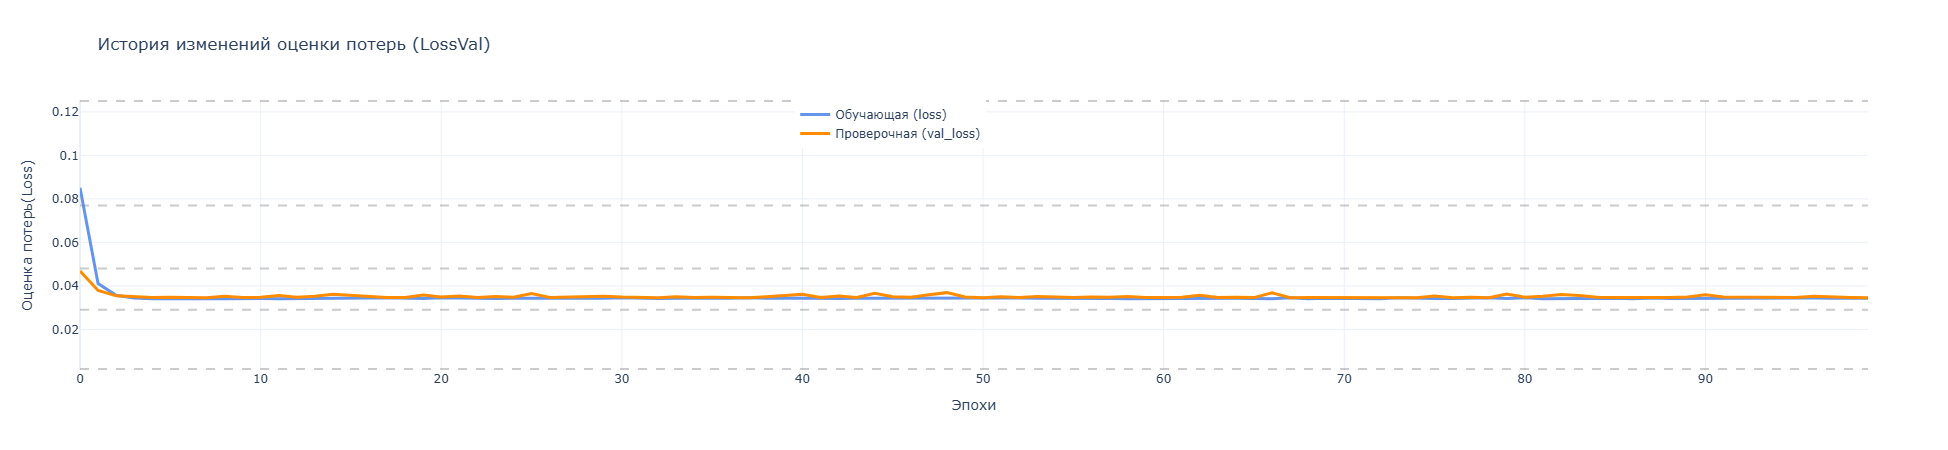

In [90]:
print('Доступные метрики полной истории обучения:', totalHistoryDict3.keys())
fig = go.Figure()
fig.add_trace(go.Scatter( y=totalHistoryDict3['loss'], mode="lines", name="Обучающая (loss)", line=dict(width=3, color='cornflowerblue')))
if 'val_loss' in totalHistoryDict3.keys():
    fig.add_trace(go.Scatter( y=totalHistoryDict3['val_loss'],  mode="lines", name="Проверочная (val_loss)",     line=dict(width=3, color='darkorange')))

refHFib = np.array([13, 8, 5, 3, 2, 1, 0.8, 0.5, 0.33, 0.2, 0.125, 0.077, 0.048,  0.029, 0.0018])
m2 = refHFib<=np.max(totalHistoryDict3['loss'])
m2 = np.concatenate([m2[1:], [True]*1])
for y in refHFib[m2]:
    fig.add_hline(y=y, line_dash="dash", line_color="gray", opacity=0.4)

fig.update_xaxes(title="Эпохи"); fig.update_yaxes(title="Оценка потерь(Loss)")
fig.update_layout(title="История изменений оценки потерь (LossVal)", template="plotly_white",
                  width=900, height=450, legend=dict(yanchor="top", x=0.4, y=1.0))
fig.show()

In [91]:
totalHistoryDict3['val_loss'][-5:]

yNorm_pred = model3.predict( xNorm_test )

GET_METRICS_SINGLE(yNorm_test, yNorm_pred)
PLOT34(yNorm_test, yNorm_pred)

79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
MAE :     0.141 (средняя абсолютная ошибка)
MSE :  0.034522 (среднеквадратичная ошибка)
RMSE:  0.185802 (кв. корень из среднеквадратичной ошибки)
R2  :     0.453 (коэфф. детерминации)


In [92]:
printModelWeights(model3)

####################################################################################################
#### Имя слоя:dense_15;  Тип слоя: <class 'keras.src.layers.core.dense.Dense'> ##########
Вид ф-ии активации слоя: linear
Кол-во ВХодов  слоя: 5
Кол-во ВЫХодов слоя: 1
Кол-во нейронов слоя:    1

Весовые коэфф. weight_i_j=
[[ 0.28036377]
 [ 0.60396725]
 [-0.5631237 ]
 [ 0.03654683]
 [-0.06621739]]

Весовые коэфф. bias_i_j=
[-0.17653728]




In [94]:
def plot_model_3d(model, model_name):
    x1 = 'Hour'
    x2 = 'Temperature(°K)'

    columns = xNorm_train.columns.tolist()
    other_columns = [c for c in columns if c not in [x1, x2]]

    fixed_values = xNorm_train.median()

    x1_values = np.linspace(0, 1, 45)
    x2_values = np.linspace(0, 1, 45)

    X1, X2 = np.meshgrid(x1_values, x2_values)

    grid = pd.DataFrame(
        np.tile(fixed_values.values, (X1.size, 1)),
        columns=columns
    )

    grid[x1] = X1.ravel()
    grid[x2] = X2.ravel()

    Y_pred_grid = model.predict(grid, verbose=0).reshape(X1.shape)

    nearby = (
        xNorm_test[other_columns]
        .sub(fixed_values[other_columns])
        .abs()
        .le(0.12)
        .all(axis=1)
    )

    fig = go.Figure()

    fig.add_trace(go.Surface(
        x=X1,
        y=X2,
        z=Y_pred_grid,
        colorscale='Viridis',
        opacity=0.7,
        showscale=False,
        name='Предсказания'
    ))

    fig.add_trace(go.Scatter3d(
        x=xNorm_test.loc[nearby, x1],
        y=xNorm_test.loc[nearby, x2],
        z=yNorm_test.loc[nearby, target[0]],
        mode='markers',
        marker=dict(size=3, color='darkorange', opacity=0.5),
        name='Проверочные данные'
    ))

    fig.update_layout(
        title=f'{model_name}: зависимость прогноза от часа и температуры',
        scene=dict(
            xaxis_title=x1,
            yaxis_title=x2,
            zaxis_title=target[0]
        ),
        width=850,
        height=650
    )

    fig.show()

In [95]:
plot_model_3d(model3, 'М3')

# Нейронная сеть m4. Построение модели со скрытыми слоями от множества "x"  (N_вх-> ??? -> ??? ->1_вых)

In [115]:
totalHistoryDict4   = dict()
globalEpochCounter = 0


model4 = tf.keras.models.Sequential()

model4.add(   tf.keras.layers.Input( shape=(  5 ,  )
))


model4.add(   tf.keras.layers.Dense(    units     = 64    ,    activation=None,))
model4.add(   tf.keras.layers.Activation(  activation = tf.keras.activations.relu, ))

model4.add(   tf.keras.layers.Dense(    units     = 32    ,    activation=None,))

model4.add(   tf.keras.layers.Activation(  activation = tf.keras.activations.relu, ))

model4.add(    tf.keras.layers.Dense(units=1,  activation=None))


model4.compile(
    loss      = tf.keras.losses.MeanSquaredError(),
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.01)
)

print("Вывод краткой информации о структуре НС")
print(model4.summary())

Вывод краткой информации о структуре НС


Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_25 (Dense)                     │ (None, 64)                  │             384 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_14 (Activation)           │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_26 (Dense)                     │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_15 (Activation)           │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_27 (Dense)                     │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,497 (9.75 KB)

 Trainable params: 2,497 (9.75 KB)

 Non-trainable params: 0 (0.00 B)

None


**Примечание к М4:** сохранённый ниже запуск обучает сеть с двумя скрытыми слоями (64 и 32) в течение 300 эпох. Первоначальное сравнение моделей М1–М4 выполнялось при 100 эпохах. Результаты отдельных запусков не смешиваются.

In [116]:
epochForTrain = 300

history = model4.fit(
    xNorm_train,
    yNorm_train,
    validation_data=(
        xNorm_test,
        yNorm_test),
    epochs=epochForTrain,
    verbose=0,
)

for key in history.history.keys():
    if key not in totalHistoryDict4.keys(): totalHistoryDict4[key]=list()
    totalHistoryDict4[key].extend(history.history[key])

Доступные метрики полной истории обучения: dict_keys(['loss', 'val_loss'])


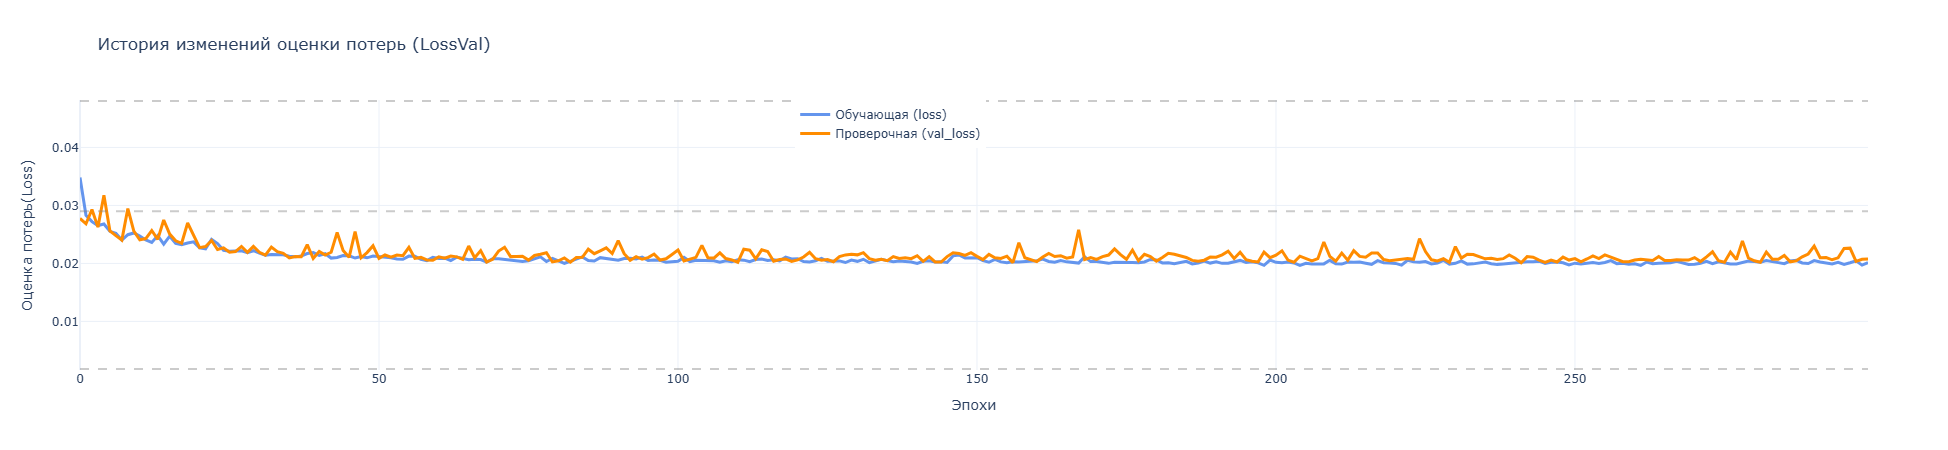

In [117]:
print('Доступные метрики полной истории обучения:', totalHistoryDict4.keys())
fig = go.Figure()
fig.add_trace(go.Scatter( y=totalHistoryDict4['loss'], mode="lines", name="Обучающая (loss)", line=dict(width=3, color='cornflowerblue')))
if 'val_loss' in totalHistoryDict4.keys():
    fig.add_trace(go.Scatter( y=totalHistoryDict4['val_loss'],  mode="lines", name="Проверочная (val_loss)",     line=dict(width=3, color='darkorange')))

refHFib = np.array([13, 8, 5, 3, 2, 1, 0.8, 0.5, 0.33, 0.2, 0.125, 0.077, 0.048,  0.029, 0.0018])
m2 = refHFib<=np.max(totalHistoryDict4['loss'])
m2 = np.concatenate([m2[1:], [True]*1])
for y in refHFib[m2]:
    fig.add_hline(y=y, line_dash="dash", line_color="gray", opacity=0.4)

fig.update_xaxes(title="Эпохи"); fig.update_yaxes(title="Оценка потерь(Loss)")
fig.update_layout(title="История изменений оценки потерь (LossVal)", template="plotly_white",
                  width=900, height=450, legend=dict(yanchor="top", x=0.4, y=1.0))
fig.show()

In [118]:
totalHistoryDict4['val_loss'][-5:]

yNorm_pred = model4.predict( xNorm_test )

GET_METRICS_SINGLE(yNorm_test, yNorm_pred)
PLOT34(yNorm_test, yNorm_pred)

79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
MAE :     0.093 (средняя абсолютная ошибка)
MSE :  0.020765 (среднеквадратичная ошибка)
RMSE:  0.144102 (кв. корень из среднеквадратичной ошибки)
R2  :     0.671 (коэфф. детерминации)


In [100]:
printModelWeights(model4)

####################################################################################################
#### Имя слоя:dense_16;  Тип слоя: <class 'keras.src.layers.core.dense.Dense'> ##########
Вид ф-ии активации слоя: linear
Кол-во ВХодов  слоя: 5
Кол-во ВЫХодов слоя: 64
Кол-во нейронов слоя:    64

Весовые коэфф. weight_i_j=
[[-6.09032691e-01 -1.25981510e+00 -1.98794082e-01 -3.10428858e-01
  -1.77058965e-01 -4.85356450e-01  1.13951601e-01  1.73976266e+00
   1.76592246e-02  3.53540219e-02  9.01549086e-02 -1.66949779e-01
  -2.52833188e-01  1.09539211e+00  8.27970624e-01 -7.54483938e-02
   1.52813643e-01 -1.46493495e+00 -3.85329008e-01 -1.40042901e-01
   5.22620939e-02 -1.10927470e-01 -4.88661194e+00  2.62915671e-01
  -4.79843974e-01 -3.90270710e+00 -2.61094809e-01 -4.93120076e-03
  -2.95417166e+00  3.69262435e-02  6.33941740e-02  1.53062567e-01
  -3.73179317e-01 -2.43459433e-01 -2.95763314e-02  4.38305765e-01
  -4.32019651e-01 -1.00059763e-01 -7.75094777e-02 -1.54083043e-01
   2.25891519e

In [103]:
plot_model_3d(model4, 'М4')

# Сравнение полученных моделей

Приведите все численные оценки всех моделей для более удобного сравнения.

Пример в текстовом виде:

      M1.
        Структура: '___'.
        Признаки: '___'.
        ЭпохОбучения: '___'.
        MAE : ___ (средняя абсолютная ошибка)
        RMSE: ___ (кв. корень из среднеквадратичной ошибки)
        R2  : ___ (коэфф. детерминации)

      M2 ...

Пример в табличном виде:

## Сравнение результатов экспериментов

**Важно:** это результаты разных запусков, а не одна таблица из одного выполнения.

### Первоначальные модели: 100 эпох

| Модель | Архитектура | R² | RMSE |
| --- | --- | ---: | ---: |
| М1 | 2 → 1 | 0,413 | 0,192430 |
| М2 | 2 → 64 → 32 → 1 | 0,584 | 0,162037 |
| М3 | 5 → 1 | 0,448 | 0,186714 |
| М4 | 5 → 64 → 32 → 1 | **0,631** | **0,152574** |

### Дополнительные эксперименты с М4

| Архитектура | Эпохи | R² | RMSE | Параметры |
| --- | --- | ---: | ---: | ---: |
| 5 → 64 → 32 → 1 | 300 | 0,671 | 0,144102 | 2 497 |
| 5 → 128 → 64 → 1 | 300 | 0,673 | 0,143640 | 9 089 |
| 5 → 256 → 128 → 1 | 300 | 0,675 | 0,143270 | 34 561 |
| 5 → 64 → 32 → 1 | 400 суммарно (продолжение обучения) | 0,684 | 0,141320 | 2 497 |

**Разные эксперименты:** результаты на 100 эпохах и с увеличенными слоями были получены в отдельных запусках. Текущий сохранённый запуск М4 — 300 эпох для 64–32. Все значения RMSE вычислены **на нормализованной шкале целевой переменной**. Рост числа параметров почти в 14 раз (64–32 → 256–128) дал небольшой прирост R²: с 0,671 до 0,675. Из-за случайной инициализации результаты повторного обучения могут отличаться.

# Итоговые, сводные результаты и выводы.

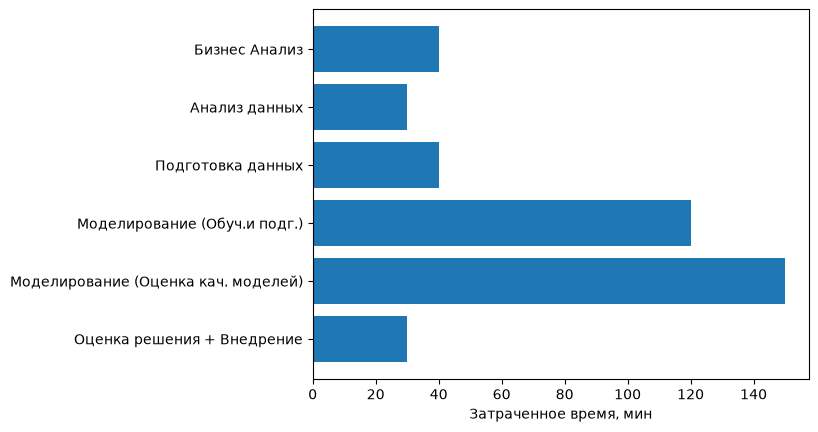

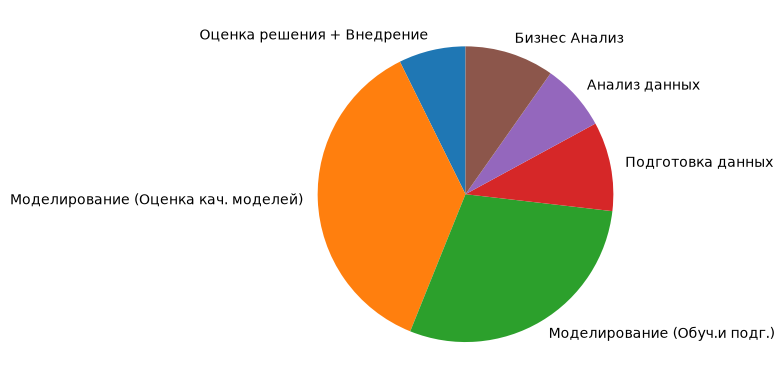

In [122]:
# Создадим датафрейм для хранения значений
dfSpendTimeLab1 = pd.DataFrame.from_dict(
{
  "1": {"step": "Бизнес Анализ",                       "duration, min" :  40  },
  "2": {"step": "Анализ данных",                       "duration, min" :  30  },
  "3": {"step": "Подготовка данных",                   "duration, min" :  40  },
  "4": {"step": "Моделирование (Обуч.и подг.)",        "duration, min" :  120 },
  "5": {"step": "Моделирование (Оценка кач. моделей)", "duration, min" :  150  },
  "6": {"step": "Оценка решения + Внедрение",          "duration, min" :  30  },
}
, orient="index"
).sort_index(ascending=False)

# Построить столбчатую диаграмму
fig = plt.figure()
plt.barh(y = dfSpendTimeLab1["step"], width= dfSpendTimeLab1["duration, min"], )
plt.xlabel("Затраченное время, мин")

# Построить круговую диаграмму
fig = plt.figure()
plt.pie(x= dfSpendTimeLab1["duration, min"], labels=dfSpendTimeLab1["step"],  startangle = 90 )

plt.show()

# Выводы по работе

- Как в целом влияет структура модели (кол-во слоев и количество нейронов на каждом слое):
  - на итоговую точность модели?
  - на время необходимое для получение приемлемых результатов?
- Оцените эффективность применения нейронных сетей на вашем наборе данных
- Сравните точность моделей m3 и m4 и сделайте предположения о причинах совпадения/различия точности

## Выводы по лабораторной работе №2

### 1. Подготовка исходных данных

В ходе лабораторной работы исследовалось применение однослойных и многослойных нейронных сетей для прогнозирования количества арендованных велосипедов в системе Seoul Bike Sharing Demand. Исходный подготовленный набор содержал 8756 наблюдений. Для выполнения требований к качеству данных проведена дополнительная фильтрация выбросов методом межквартильного размаха (IQR). Для признаков с преобладанием нулевых значений применена отдельная обработка положительных наблюдений, чтобы не считать любое выпадение осадков аномалией. В ходе фильтрации было удалено 385 строк. Очищенный набор сохранён в отдельный CSV-файл для повторного использования.

В качестве целевой переменной выбрано количество арендованных велосипедов (Rented Bike Count). В моделях М1 и М2 использовались два входных признака: час суток и температура воздуха. В М3 и М4 дополнительно использовались количество дождевых осадков, скорость ветра и количество снега. Признаки и целевая переменная нормализованы методом MinMaxScaler до диапазона [0; 1]. Нормализация привела значения к единому масштабу без изменения формы распределений. После подготовки выборка разделена случайным образом на обучающую (70%, 5859 наблюдений) и проверочную (30%, 2512 наблюдений) части.

### 2. Исследование архитектуры нейронных сетей

Построены четыре модели регрессии:
- М1: 2 → 1, без скрытых слоёв;
- М2: 2 → 64 → 32 → 1, с двумя скрытыми слоями;
- М3: 5 → 1, без скрытых слоёв;
- М4: 5 → 64 → 32 → 1, с двумя скрытыми слоями.

М1 и М2 обучались на одинаковых двух входных признаках. М3 и М4 — на одинаковых пяти входных признаках. Для скрытых слоёв М2 и М4 использовалась функция активации ReLU. Выходной слой каждой модели имел один нейрон без нелинейной функции активации, что соответствует задаче регрессии. Для обучения использовались функция потерь MSE и оптимизатор Adam со скоростью обучения 0,01. Первоначальное обучение всех четырёх моделей проводилось в течение 100 эпох.

### 3. Сравнение качества моделей

По результатам первоначального обучения были получены следующие показатели коэффициента детерминации R²: М1 — 0,413; М2 — 0,584; М3 — 0,448; М4 — 0,631. Наименьший RMSE показала модель М4 — 0,1526. Наибольший RMSE наблюдался у М1 — 0,1924. Все значения MAE, MSE и RMSE рассчитывались в нормализованном масштабе целевой переменной.
Сравнение М1 и М2 показало, что добавление двух скрытых слоёв повысило R² на 0,171. Для М3 и М4 соответствующее увеличение составило 0,183.
Добавление трёх входных признаков также улучшило качество: R² увеличился с 0,413 до 0,448 при сравнении М1 и М3 и с 0,584 до 0,631 при сравнении М2 и М4.
Таким образом, в данном эксперименте использование нелинейных скрытых слоёв оказало более выраженное влияние на качество прогнозирования, чем увеличение количества входных признаков с двух до пяти.

### 4. Анализ обучения и графиков

Графики изменения функции потерь показали снижение ошибок в процессе обучения. Для линейных моделей М1 и М3 стабилизация происходила быстрее, тогда как многослойные сети продолжали постепенно улучшать результаты. Графики фактических и предсказанных значений показали, что все модели испытывают трудности при прогнозировании части наблюдений, особенно при больших значениях спроса. На графиках квадратов ошибок заметны отдельные наблюдения с существенными отклонениями.

Трёхмерная визуализация моделей М1 и М2 использовалась для отображения зависимости прогноза от часа суток и температуры. Для моделей М3 и М4 с пятью входными признаками строились двумерные срезы зависимости в трёхмерном пространстве: три остальных признака фиксировались на медианных значениях обучающей выборки.

Для линейных моделей прогнозируемая зависимость представляется плоскостью. Многослойные сети благодаря ReLU способны формировать кусочно-линейные нелинейные поверхности.

### 5. Эксперимент с количеством нейронов

Для исследования влияния размера нейронной сети дополнительно обучены три варианта М4 с архитектурами скрытых слоёв 64–32, 128–64 и 256–128. Каждый вариант обучался в течение 300 эпох. При увеличении количества скрытых нейронов с 96 до 384 коэффициент R² вырос с 0,671 до 0,675, а RMSE уменьшился с 0,14410 до 0,14327. Одновременно количество обучаемых параметров увеличилось с 2497 до 34561, то есть почти в 14 раз. Полученный прирост качества оказался небольшим по сравнению с ростом сложности сети. Это показывает, что увеличение числа нейронов не гарантирует существенного улучшения прогнозирования.

Для рассматриваемого набора данных архитектура 64–32 обеспечивает сопоставимое качество при значительно меньшем числе параметров.

### 6. Эксперимент с продолжительностью обучения

Отдельно исследовано дополнительное обучение первоначальной М4. После суммарно 400 эпох коэффициент R² составил 0,684, а RMSE — 0,14132. По сравнению с первоначальными 100 эпохами результат улучшился, но график функции потерь показал постепенное замедление снижения ошибки.
Таким образом, увеличение продолжительности обучения оказалось полезным, однако дополнительные эпохи дают убывающий прирост качества. Поскольку сравнивались отдельные запуски и режимы обучения, часть различий могла зависеть от случайной инициализации и траектории оптимизации.

### 7. Общий вывод

В результате лабораторной работы реализованы и исследованы четыре нейронные сети для решения задачи регрессии, выполнены нормализация данных, обучение моделей, расчёт метрик качества и визуализация результатов. Установлено, что многослойные сети с нелинейными функциями активации лучше описывают рассматриваемую зависимость, чем модели без скрытых слоёв. Наилучший результат среди четырёх основных моделей показала М4. Дополнительные эксперименты подтвердили, что увеличение количества нейронов в скрытых слоях не всегда экономически и вычислительно оправданно: усложнение сети в несколько раз дало лишь незначительное повышение R². Для дальнейшего улучшения результатов целесообразнее исследовать дополнительные информативные признаки и способы представления времени, а также провести более строгую независимую оценку качества, прежде чем продолжать увеличивать размер модели.